<div align="center">

# UNIVERSIDAD SALESIANA DE BOLIVIA
### Subsede Académica Cochabamba · Carrera de Ingeniería de Sistemas

---

## SIMULADOR DE PROPAGACIÓN DE INCENDIOS FORESTALES CON AUTÓMATAS CELULARES Y MONTE CARLO, APOYADO POR DRON TÉRMICO, PARA PLANIFICAR LÍNEAS CORTAFUEGOS EN EL SECTOR CERCADO DEL PARQUE NACIONAL TUNARI

**Cuaderno Jupyter del modelo de simulación — Grupo 3**

Proyecto de Aprendizaje Basado en Proyectos (ABP) · Concurso de los Mejores Proyectos ABP – Gestión Académica 2/2026
Línea orientadora: Aguinaldo Salesiano 2026 — «Haced lo que Él os diga» – Creyentes, libres para servir

</div>

| Dato | Detalle |
|---|---|
| **Asignatura** | Simulación y Modelación (SIM-522) — Décimo semestre |
| **Docente responsable** | Mgr. Franz Guaman Rivera |
| **Integrantes** | Zambrana Cespedes, Samira Estephany (61071) — Coordinación<br>Romero Chavez, Oscar Enrique (57353) — Campo y datos<br>Chino Ferrufino, Rimer Joel (61389) — Modelado en Python<br>Argollo Mamani, Melvy Alison (61144) — Interfaz Tkinter y documentación |
| **Beneficiarios** | Unidad de Gestión de Riesgos (UGR) de la Alcaldía de Cochabamba, bomberos forestales y voluntarios del Parque Nacional Tunari, familias de la zona norte de Cercado |
| **Sector** | Ladera sur del Parque Nacional Tunari sobre el municipio de Cercado: grilla de 100 × 100 celdas de 25 m (2,5 × 2,5 km = 6,25 km²) |
| **Técnica** | Autómata celular probabilístico (Alexandridis et al., 2008) + Monte Carlo (Unidad IV; números aleatorios, Unidades II y III) |
| **Lugar y fecha** | Cochabamba – Bolivia, noviembre de 2026 |

## Índice

0. [Cómo usar este cuaderno y origen de los datos](#0)
1. [Fase 1: el problema y las preguntas guía](#1)
2. [Conceptos que necesitamos](#2)
3. [Librerías](#3)
4. [PARTE A — Los datos reales (**dataset**): NASA FIRMS, clima, terreno e incendios](#4)
5. [Ajuste de distribuciones](#5)
6. [PARTE B — **Variables aleatorias** y prueba del generador](#6)
7. [Comparación: dataset vs. variables aleatorias](#7)
8. [El autómata celular](#8)
9. [Verificación](#9)
10. [Calibración y validación con el incendio del 12 de agosto de 2026](#10)
11. [Experimentos de Monte Carlo: cortafuegos, eucalipto, tiempo de respuesta y peor día](#11)
12. [Resultados, mapa de riesgo y recomendación para la UGR](#12)
13. [Aguinaldo Salesiano, ética y limitaciones](#13)
14. [Preparación para la interfaz Tkinter](#14)
15. [Referencias](#15)

<a id="0"></a>
## 0. Cómo usar este cuaderno y origen de los datos

Ejecute las celdas en orden con **Shift + Enter** (o *Kernel → Restart & Run All*). La carpeta `datos/` debe estar junto al cuaderno. Las corridas de Monte Carlo de la sección 11 tardan algunos minutos.

| Archivo (`datos/`) | Contenido | Origen | ¿Real? |
|---|---|---|---|
| `focos_firms_tunari_2020_2025.csv` | Focos de calor de la ladera sur del Tunari (MODIS, VIIRS S-NPP y VIIRS NOAA-20), 2020–2025 | **NASA FIRMS**, archivo anual por país (Bolivia), recortado al rectángulo 17,22°–17,45° S y 65,95°–66,45° O | **Sí**, descargado el 5/11/2026 |
| `meteo_tunari_epoca_seca_2023_2026.csv` | Serie **horaria** de temperatura, humedad, lluvia, velocidad, dirección y ráfagas de viento a 10 m, julio–octubre de 2023 a 2026 | **Open-Meteo** Historical Weather API (reanálisis ERA5/ERA5-Land) para 17,344° S, 66,160° O | **Sí** |
| `grilla_sector_cercado.csv` | Las 10.000 celdas: fila, columna, coordenadas, **elevación**, cobertura y densidad | Elevación: **Copernicus DEM GLO-90** vía Open-Meteo Elevation API. Cobertura: **aproximación** del equipo (ver nota) | Elevación **sí**; cobertura **aproximada** |
| `incendios_documentados.csv` | Incendios de 2025–2026 con fecha, sector, superficie, horas y fuente | Prensa y reportes oficiales (Planilla 3.1, Tabla 6 del informe) | Sí |
| `cifras_oficiales.csv` | Cortes oficiales de incendios y hectáreas | Gobernación, Sernap, Alcaldía (Tabla 8 del informe) | Sí |
| `parametros_modelo.csv` | Parámetros del autómata y de la respuesta | Alexandridis et al. (2008) y supuestos declarados | — |

**Nota sobre la cobertura vegetal.** La clasificación definitiva se hará recortando **ESA WorldCover 10 m** en QGIS (procedimiento en la sección 4.3). Mientras tanto, la capa de cobertura de este cuaderno es una **aproximación** construida a partir de la elevación real y de lo que se observa en el sector (zona urbana al pie, franja de eucalipto y pino, pajonal dominante —el 80,8 % de lo quemado en 2026 fue pajonal—, matorral en quebradas y roca en lo alto). Al reemplazar el CSV por la capa de WorldCover, **el resto del cuaderno funciona sin cambios**.

<a id="1"></a>
## 1. Fase 1: el problema que estudiamos

Cada época seca (julio a octubre) arden las laderas del Parque Nacional Tunari. Hasta el 2 de septiembre de 2026 se registraron **26 incendios y 744,5 ha** quemadas en el parque; el del **12 de agosto de 2026** en Cercado quemó **~43 ha en ~3 h 20 min** y destruyó dos cabañas, una granja avícola y colmenas. Los bomberos deciden por experiencia **dónde abrir un cortafuegos y cuántas cuadrillas enviar**; un incendio real no se puede repetir para probar alternativas, pero sí se puede **simular**.

### 1.1 Respuestas a las preguntas guía de la Fase 1

| Pregunta guía (Descripción de los proyectos, §3.10) | Nuestra respuesta |
|---|---|
| ¿Qué sector exacto estudian, qué superficie tiene y qué se quiere proteger? | Ladera sur del Tunari sobre **Cercado (zona norte)**: rectángulo de **2,5 × 2,5 km (6,25 km²)** entre 17,3325° y 17,3550° S y entre 66,1717° y 66,1483° O, de ~2.700 a ~3.050 m s. n. m. Se protege el **borde urbano de la zona norte** (viviendas al pie del sector). |
| ¿Cuántos incendios hubo y cuántas hectáreas se perdieron? | 2015–2019: 7.123 ha en el Tunari (2.315 ha en Cercado). 2026 (al 2/09): 26 incendios y 744,5 ha. Los **focos NASA FIRMS 2020–2025** de la ladera sur se analizan en la sección 4.1. |
| ¿Qué factores hacen que el fuego avance más rápido? | **Pajonal seco** (80,8 % de lo quemado), **eucalipto y pino**, **pendiente** (el fuego sube más rápido), **viento** (predomina del suroeste por la tarde, es decir, empuja el fuego ladera arriba) y **baja humedad** (mediana ~23 % en las tardes de época seca, sección 4.2). |
| ¿Qué decisión de prevención o respuesta necesita tomar quien protege la zona? | **Dónde construir una línea cortafuegos**, a qué distancia de las viviendas, **cuántas cuadrillas** asignar y **cuánto tiempo** hay para hacerlo; si conviene retirar eucalipto junto a las casas. |
| ¿A quién entregarán sus resultados y cómo podrán usarlos? | A la **UGR de Cercado** y a los bomberos forestales: mapa de riesgo, tabla de escenarios y la aplicación Tkinter para capacitar a voluntarios. |

**Formulación del problema:** ¿Cómo un simulador de propagación de incendios basado en autómatas celulares y Monte Carlo, alimentado con el estado del fuego observado por un dron térmico o por satélite, permitirá a la UGR y a los bomberos forestales de Cercado decidir a qué distancia y por dónde construir una línea cortafuegos, y cuántas cuadrillas asignar, para contener los incendios del sector Cercado del Parque Nacional Tunari antes de que alcancen las viviendas?

| Objetivo específico (informe, §2.2.2) | Sección |
|---|---|
| OE1. Diagnosticar con focos NASA FIRMS 2020–2025, incendios documentados y entrevistas | 4 |
| OE2. Construir el autómata con capas de vegetación y elevación y un generador de números pseudoaleatorios validado | 6, 8, 9 |
| OE3. Calibrar y validar con el incendio del 12/08/2026 | 10 |
| OE4. Comparar escenarios de cortafuegos y recursos con Monte Carlo e IC 95 % | 11 |
| OE5. Interfaz Tkinter y entrega a la UGR | 12, 14 |

### 1.2 El sistema que vamos a modelar (§3.4)

| Elemento | En nuestro modelo |
|---|---|
| **Espacio** | Grilla de 100 × 100 celdas de 25 m (0,0625 ha por celda) |
| **Estados** | 0 = no quemable (roca, urbano, cortafuegos) · 1 = combustible · 2 = en llamas · 3 = quemada |
| **Atributos** | Tipo de vegetación, densidad, elevación |
| **Vecindad** | Moore (8 vecinas) |
| **Regla** | $p_{burn} = p_h (1 + p_{veg})(1 + p_{den})\, p_w\, p_s$ por cada vecina en llamas |
| **Aleatoriedad** | U(0,1) para cada ignición; Monte Carlo sobre el punto de inicio y el viento |
| **Medidas** | Hectáreas quemadas, tiempo hasta el borde urbano, probabilidad de alcanzar las viviendas |

<a id="2"></a>
## 2. Conceptos que necesitamos

| Concepto | Idea | Referencia |
|---|---|---|
| **Autómata celular** | Grilla de celdas con estados que cambian en pasos de tiempo según reglas **locales** que dependen de las vecinas | Wolfram (2002); Alexandridis et al. (2008) |
| **Vecindad de Moore** | Las 8 celdas que rodean a una celda (4 lados + 4 diagonales) | Alexandridis et al. (2008) |
| **Efecto del viento** $p_w$ | $p_w = \exp\big(V\,[c_1 + c_2(\cos\varphi - 1)]\big)$, con $V$ en m/s y $\varphi$ el ángulo entre el viento y la dirección de propagación: a favor del viento $p_w > 1$, en contra $p_w < 1$ | Alexandridis et al. (2008) |
| **Efecto de la pendiente** $p_s$ | $p_s = \exp(a\,\theta)$, con $\theta$ el ángulo de la pendiente hacia la celda vecina (positivo cuesta arriba): **el fuego sube más rápido que lo que baja** | Alexandridis et al. (2008) |
| **Monte Carlo** | Repetir la simulación muchas veces con números aleatorios distintos y resumir con promedios, probabilidades e IC. Con N corridas, el error estándar de una probabilidad es $\sqrt{p(1-p)/N}$ | Banks et al. (2010); Law (2015) |
| **NASA FIRMS** | Focos de calor detectados por satélite (MODIS 1 km; VIIRS 375 m) con fecha, hora UTC e intensidad (FRP) | Schroeder et al. (2014); Giglio et al. (2016) |
| **Ataque indirecto** | Construir la línea de control a cierta distancia del fuego y sacrificar el combustible intermedio | NWCG (s.f.) |

<a id="3"></a>
## 3. Librerías

Solo usamos NumPy (Harris et al., 2020), pandas (McKinney, 2010), SciPy (Virtanen et al., 2020) y Matplotlib (Hunter, 2007). El autómata se programa con **operaciones sobre arreglos completos** de NumPy, lo que permite correr cientos de incendios en segundos.

In [1]:
import copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import stats, ndimage

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
print("NumPy", np.__version__)

NumPy 2.5.3


<a id="4"></a>
## 4. PARTE A — Los datos reales (dataset)

### 4.1 Focos de calor NASA FIRMS 2020–2025

Cada fila es un píxel en el que un satélite detectó una anomalía térmica. Columnas principales: `latitude`, `longitude`, `acq_date`, `acq_time` (hora **UTC**, formato HHMM), `confidence` (MODIS: 0–100; VIIRS: *l*ow, *n*ominal, *h*igh), `frp` (potencia radiativa del fuego, MW) y `type` (0 = vegetación presunta). Como Bolivia está en UTC−4, **restamos 4 horas** para obtener la hora local (protocolo del informe, §4.3).

In [2]:
D = "datos/"
focos = pd.read_csv(D + "focos_firms_tunari_2020_2025.csv")
focos["fecha"] = pd.to_datetime(focos.acq_date)
focos["hora_utc"] = focos.acq_time // 100 + (focos.acq_time % 100) / 60
focos["hora_local"] = (focos.hora_utc - 4) % 24
focos["anio"] = focos.fecha.dt.year; focos["mes"] = focos.fecha.dt.month
# Filtro de calidad: descartamos detecciones de baja confianza y las que no son de vegetación
conf_baja = ((focos.instrument == "MODIS") & (focos.confidence.astype(str).str.isnumeric()) &
             (pd.to_numeric(focos.confidence, errors="coerce") < 30)) | (focos.confidence.astype(str) == "l")
focos_ok = focos[~conf_baja & (focos.type == 0)].copy()
print(f"Focos descargados: {len(focos)}  |  tras el filtro de calidad: {len(focos_ok)}")
display(focos_ok.groupby(["anio", "sensor"]).size().unstack(fill_value=0))

Focos descargados: 1934  |  tras el filtro de calidad: 1679


sensor,"MODIS (Terra/Aqua, 1 km)",VIIRS NOAA-20 (375 m),VIIRS S-NPP (375 m)
anio,,,
2020,49,225,259
2021,8,113,75
2022,23,133,126
2023,11,113,107
2024,10,143,103
2025,10,88,83


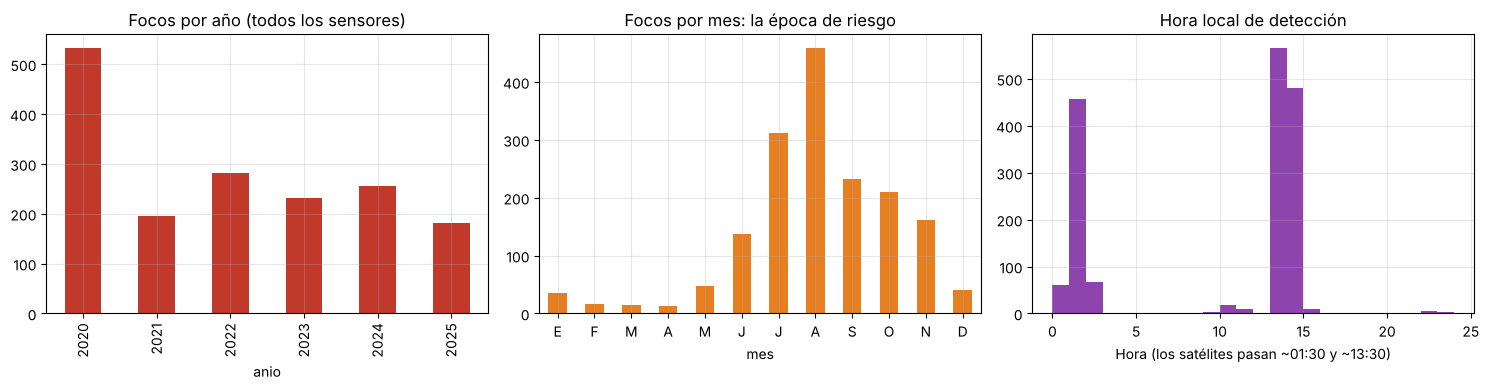

El 72 % de los focos ocurre entre julio y octubre (época seca).


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
focos_ok.groupby("anio").size().plot(kind="bar", ax=axs[0], color="#c0392b"); axs[0].set_title("Focos por año (todos los sensores)")
focos_ok.groupby("mes").size().reindex(range(1, 13), fill_value=0).plot(kind="bar", ax=axs[1], color="#e67e22")
axs[1].set_title("Focos por mes: la época de riesgo"); axs[1].set_xticklabels(["E","F","M","A","M","J","J","A","S","O","N","D"], rotation=0)
axs[2].hist(focos_ok.hora_local, bins=24, range=(0, 24), color="#8e44ad"); axs[2].set_title("Hora local de detección")
axs[2].set_xlabel("Hora (los satélites pasan ~01:30 y ~13:30)"); plt.tight_layout(); plt.show()
pct_seca = 100 * focos_ok.mes.between(7, 10).mean()
print(f"El {pct_seca:.0f} % de los focos ocurre entre julio y octubre (época seca).")

**Interpretación.** La mayoría de los focos se concentra entre **julio y octubre**, como esperábamos. Las horas de detección se agrupan en dos momentos porque los satélites pasan pocas veces al día: un foco indica que el fuego **estaba activo** a esa hora, no cuándo empezó (Schroeder et al., 2014).

**Mapa de focos y ubicación del sector.** El rectángulo rojo es nuestro sector de Cercado (grilla de 100 × 100 celdas). El rectángulo de descarga incluye también parte de la ciudad (al sur de ~17,37° S), donde los focos suelen ser quemas de basura o fuentes industriales; para el parque interesan los focos de la ladera (al norte).

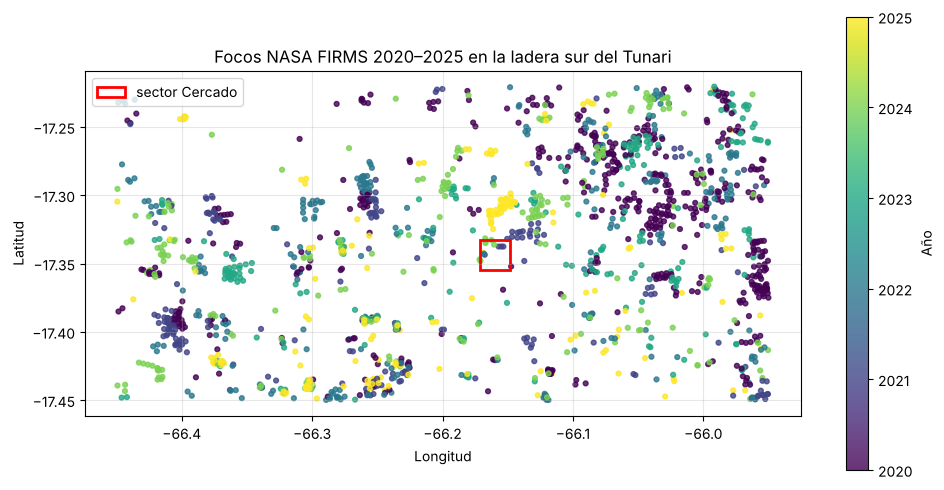

Focos dentro del sector: 12  |  dentro o a menos de ~1 km: 24


In [4]:
grilla = pd.read_csv(D + "grilla_sector_cercado.csv")
N = int(grilla.fila.max() + 1); CELDA = 25.0; HA_CELDA = CELDA**2 / 10000
lat_min, lat_max = grilla.lat.min(), grilla.lat.max(); lon_min, lon_max = grilla.lon.min(), grilla.lon.max()

fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(focos_ok.longitude, focos_ok.latitude, c=focos_ok.anio, cmap="viridis", s=12, alpha=0.8)
ax.add_patch(plt.Rectangle((lon_min, lat_min), lon_max - lon_min, lat_max - lat_min, fill=False, ec="red", lw=2, label="sector Cercado"))
plt.colorbar(sc, label="Año"); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.legend()
ax.set_title("Focos NASA FIRMS 2020–2025 en la ladera sur del Tunari"); ax.set_aspect(1 / np.cos(np.radians(17.35)))
plt.tight_layout(); plt.show()

margen = 0.01   # ~1 km alrededor del sector
cerca = focos_ok[focos_ok.latitude.between(lat_min - margen, lat_max + margen) & focos_ok.longitude.between(lon_min - margen, lon_max + margen)]
dentro = focos_ok[focos_ok.latitude.between(lat_min, lat_max) & focos_ok.longitude.between(lon_min, lon_max)]
print(f"Focos dentro del sector: {len(dentro)}  |  dentro o a menos de ~1 km: {len(cerca)}")

### 4.2 Clima de la época seca (Open-Meteo, serie horaria real)

Nos interesan las **tardes** (12:00–18:00), cuando ocurren y crecen los incendios. **Ojo con la dirección del viento:** en meteorología se informa **de dónde viene** el viento (270° = viene del oeste). El fuego avanza **hacia donde va** el viento (dirección + 180°).

,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m
count,3444.0,3444.0,3444.0,3444.0
mean,21.8,23.9,6.4,28.5
std,2.9,13.4,3.3,7.3
min,8.5,1.0,0.0,10.8
25%,20.1,13.0,4.1,23.4
50%,21.9,23.0,6.1,28.1
75%,23.8,32.0,8.2,32.4
max,29.9,91.0,22.5,73.1


Máximo de días seguidos sin lluvia en la serie: 40


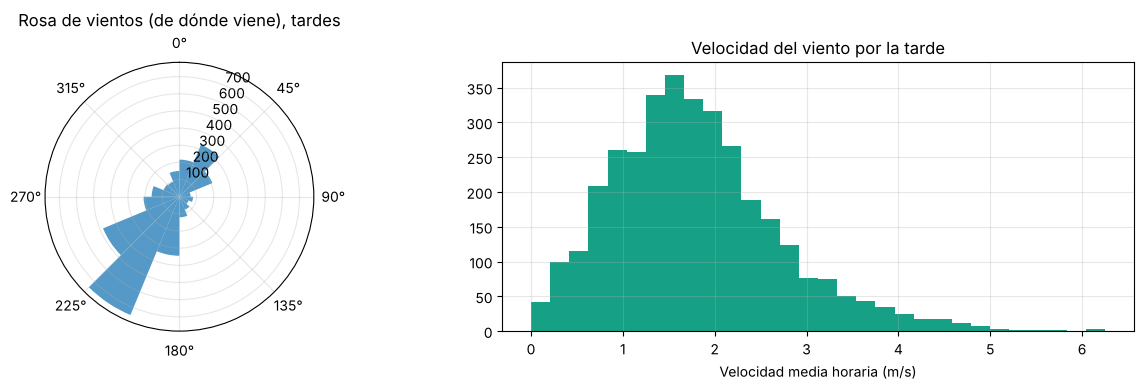

In [5]:
meteo = pd.read_csv(D + "meteo_tunari_epoca_seca_2023_2026.csv", parse_dates=["time"])
meteo["hora"] = meteo.time.dt.hour
tarde = meteo[meteo.hora.between(12, 18)].copy()
tarde["V_ms"] = tarde.wind_speed_10m / 3.6                      # km/h -> m/s (el modelo usa m/s)
display(tarde[["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "wind_gusts_10m"]].describe().round(1))

lluvia_dia = meteo.groupby(meteo.time.dt.date).precipitation.sum()
racha = (lluvia_dia < 0.5).astype(int); racha = racha.groupby((racha == 0).cumsum()).cumsum()
print(f"Máximo de días seguidos sin lluvia en la serie: {racha.max()}")

fig = plt.figure(figsize=(13, 4))
ax1 = fig.add_subplot(1, 2, 1, projection="polar")
ang = np.radians(tarde.wind_direction_10m)
hist, bins_ = np.histogram(ang, bins=16, range=(0, 2 * np.pi))
ax1.bar(bins_[:-1], hist, width=2 * np.pi / 16, align="edge", color="#2980b9", alpha=0.8)
ax1.set_theta_zero_location("N"); ax1.set_theta_direction(-1); ax1.set_title("Rosa de vientos (de dónde viene), tardes")
ax2 = fig.add_subplot(1, 2, 2); ax2.hist(tarde.V_ms, bins=30, color="#16a085")
ax2.set_xlabel("Velocidad media horaria (m/s)"); ax2.set_title("Velocidad del viento por la tarde"); plt.tight_layout(); plt.show()

**Interpretación.** Por la tarde el viento viene sobre todo del **suroeste** (sopla hacia el noreste, es decir, **ladera arriba**, hacia el parque). Esto favorece que un fuego iniciado cerca de las casas suba hacia el parque; el peligro para las viviendas aparece cuando el fuego empieza **más arriba** y el viento sopla del norte o noreste (empujándolo ladera abajo). La velocidad media horaria es moderada (≈ 2 m/s), pero las **ráfagas** superan 8 m/s con frecuencia: lo usaremos en el escenario «peor día».

### 4.3 El terreno: elevación real y cobertura

**Procedimiento para la capa definitiva (QGIS):** reproyectar ESA WorldCover y el DEM a UTM 19 S (EPSG:32719), recortar al rectángulo, remuestrear a 25 m y exportar las celdas a CSV con las mismas columnas que `grilla_sector_cercado.csv`.

La **pendiente** entre una celda y su vecina es $\theta = \arctan\!\left(\frac{\Delta z}{d}\right)$, con $d = 25$ m (lados) o $25\sqrt2$ m (diagonales).

,celdas,hectareas,porcentaje
clase_esa,,,
Pastizal (pajonal),4440,277.50,44.40
Zona construida,2018,126.12,20.18
Arbórea (eucalipto/pino),1391,86.94,13.91
Matorral,1126,70.38,11.26
Roca / suelo desnudo,729,45.56,7.29
Cultivo,287,17.94,2.87
Agua,9,0.56,0.09


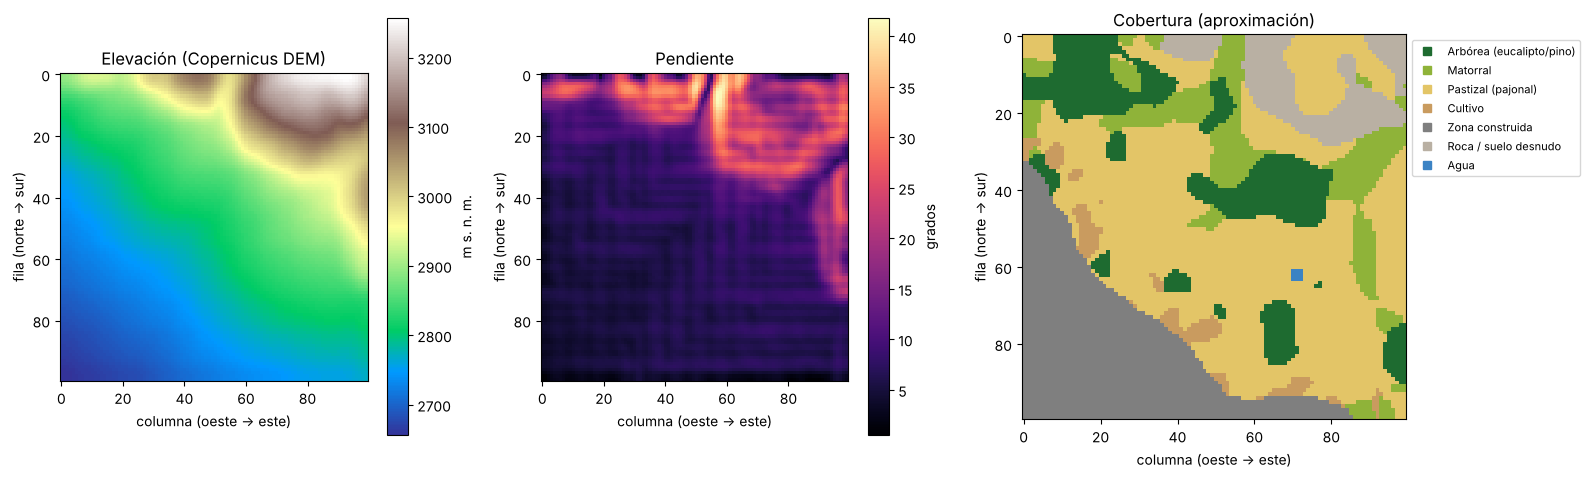

Elevación: 2656 a 3257 m; pendiente media 10.9°, máxima 41.8°


In [6]:
def a_matriz(col):
    return grilla.pivot(index="fila", columns="col", values=col).values

ELEV = a_matriz("elevacion_m").astype(float)
CLASE = a_matriz("clase_esa").astype(int)
DENS = a_matriz("densidad_ajuste").astype(float)

NOMBRES_CLASE = {10: "Arbórea (eucalipto/pino)", 20: "Matorral", 30: "Pastizal (pajonal)", 40: "Cultivo",
                 50: "Zona construida", 60: "Roca / suelo desnudo", 80: "Agua"}
tabla_cob = (grilla.clase_esa.value_counts().rename(index=NOMBRES_CLASE).to_frame("celdas")
             .assign(hectareas=lambda d: d.celdas * HA_CELDA, porcentaje=lambda d: 100 * d.celdas / d.celdas.sum()))
display(tabla_cob)

gy, gx = np.gradient(ELEV, CELDA)
pend = np.degrees(np.arctan(np.hypot(gx, gy)))
colores = {10: "#1e6b30", 20: "#8fb339", 30: "#e3c567", 40: "#c99b5f", 50: "#7f7f7f", 60: "#b9b0a3", 80: "#3b83c4"}
codigos = sorted(colores); cmap_cob = ListedColormap([colores[c] for c in codigos])
idx_cob = np.vectorize({c: i for i, c in enumerate(codigos)}.get)(CLASE)

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
im = axs[0].imshow(ELEV, cmap="terrain"); plt.colorbar(im, ax=axs[0], label="m s. n. m."); axs[0].set_title("Elevación (Copernicus DEM)")
im = axs[1].imshow(pend, cmap="magma"); plt.colorbar(im, ax=axs[1], label="grados"); axs[1].set_title("Pendiente")
axs[2].imshow(idx_cob, cmap=cmap_cob, vmin=-0.5, vmax=len(codigos) - 0.5); axs[2].set_title("Cobertura (aproximación)")
for c in codigos: axs[2].plot([], [], "s", color=colores[c], label=NOMBRES_CLASE[c])
axs[2].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
for a in axs: a.set_xlabel("columna (oeste → este)"); a.set_ylabel("fila (norte → sur)"); a.grid(False)
plt.tight_layout(); plt.show()
print(f"Elevación: {ELEV.min():.0f} a {ELEV.max():.0f} m; pendiente media {pend.mean():.1f}°, máxima {pend.max():.1f}°")

### 4.4 Incendios documentados y cifras oficiales

In [7]:
incendios = pd.read_csv(D + "incendios_documentados.csv"); display(incendios)
cifras = pd.read_csv(D + "cifras_oficiales.csv"); display(cifras)

,n,fecha,sector,municipio,superficie_ha,hora_inicio,duracion,causa_reportada,fuente,observacion
0,1,2026-10-17,Laguna Wara Wara,Cercado,0.5,~11:00 (detección),No informada,Chaqueo para preparar terreno de siembra,Eju.tv (2026),Fecha de la nota
1,2,2026-10-13,Bellavista – Pocopampa,Sacaba,NaN,~12:30,~7 h (controlado 19:30),No informada,Los Tiempos (2026b),NaN
2,3,2026-10-06,Potrero,Quillacollo,10.0,No informada,"6 a 8 días, 6 reactivaciones",No informada; el viento agravó la propagación,Los Tiempos (2026b),Fecha inferida
3,4,2026-08-31,"Arocagua, Los Arévalos y Larati",Sacaba,NaN,No informada,Hasta la madrugada del 01/09,Presunto descuido,Los Tiempos (2026a),NaN
4,5,2026-08-12,Cercado (zona no precisada),Cercado,43.0,15:10,~3 h 20 min (control 18:30),Presuntamente provocado (en investigación),Éxito Noticias (2026),INCENDIO DE REFERENCIA
5,A1,2026-06-22,Leuquepampa,Cercado,50.0,No informada,22 y 23 de junio,No informada,Red Uno (2026),Antecedente; >50 ha
6,A2,2026-07-29,Candelaria,Cercado,6.0,No informada,No informada,No informada,El Diario (2026a),Antecedente
7,A3,2025-08-22,Parque Tunari,No precisado,350.0,No informada,No informada,No informada,Opinión (2025),Antecedente; >350 ha


,corte,departamento_cochabamba,parque_nacional_tunari,fuente
0,Al 25/06/2025,8 incendios · 51 ha,"6 incendios · 41,5 ha",Opinión (2026)
1,Al 25/06/2026,"18 incendios · 194,5 ha","10 incendios · ~123,5 ha",Opinión (2026)
2,Al 02/09/2026,"57 incendios · 2.437,5 ha","26 incendios · 744,5 ha",Los Tiempos (2026a)
3,Inicios de octubre de 2026,83 incendios · 6.951 ha,Sin desglose,El Diario (2026b)
4,Gestión 2025 completa,2.489 ha,Sin desglose,El Diario (2026b)
5,2015–2019 (acumulado),—,7.123 ha (Cercado: 2.315 ha; peor año 2016: 3....,Los Tiempos (2020)


**Incendio de referencia (12/08/2026, Cercado):** ~43 ha entre las 15:10 y las 18:30 (~200 min), es decir ~12,9 ha/h. Con celdas de 25 m (0,0625 ha) son **≈ 688 celdas en 200 minutos**. Es el único con hora de inicio y de control publicadas, por eso sirve para fijar **cuántos minutos reales representa un paso** del autómata (sección 10). Además, gracias a Open-Meteo tenemos el **viento real de esa tarde**:

In [8]:
ref = meteo[(meteo.time >= "2026-08-12 15:00") & (meteo.time <= "2026-08-12 18:00")]
display(ref[["time", "temperature_2m", "relative_humidity_2m", "wind_speed_10m", "wind_direction_10m", "wind_gusts_10m"]])
V_REF = ref.wind_speed_10m.mean() / 3.6
DIR_REF = np.degrees(np.arctan2(np.sin(np.radians(ref.wind_direction_10m)).mean(), np.cos(np.radians(ref.wind_direction_10m)).mean())) % 360
print(f"Viento medio de la tarde del 12/08/2026: {V_REF:.2f} m/s, viniendo de {DIR_REF:.0f}° (oeste-suroeste)")

,time,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_direction_10m,wind_gusts_10m
9879,2026-08-12 15:00:00,21.4,24,7.0,291,33.1
9880,2026-08-12 16:00:00,20.9,25,6.5,284,33.8
9881,2026-08-12 17:00:00,20.0,27,6.1,268,31.3
9882,2026-08-12 18:00:00,18.5,28,10.5,233,35.6


Viento medio de la tarde del 12/08/2026: 2.09 m/s, viniendo de 269° (oeste-suroeste)


<a id="5"></a>
## 5. Ajuste de distribuciones

Para el modo aleatorio necesitamos distribuciones para el **viento** (velocidad y dirección) y para el **punto de inicio**.

- **Velocidad del viento → Weibull.** Es la distribución clásica de la velocidad del viento (Justus et al., 1978). Se ajusta por máxima verosimilitud y se prueba con K-S.
- **Dirección → mezcla de dos von Mises.** La von Mises es la «normal» de los ángulos (Fisher, 1993). Como hay dos direcciones frecuentes (suroeste y noreste), usamos una **mezcla de dos** componentes.
- **Punto de inicio.** Modo dataset: celdas cercanas a focos FIRMS reales. Modo aleatorio: cualquier celda combustible del sector a más de 300 m de las viviendas, con igual probabilidad.

Weibull: forma k = 2.06, escala λ = 2.02 m/s  |  K-S D = 0.036, p = 0.000
Nota: con más de 3.000 datos, el K-S detecta diferencias mínimas; por eso juzgamos también con el gráfico Q-Q.


Componente 1: peso 0.53, viene de 218°, concentración κ = 6.14
Componente 2: peso 0.47, viene de 22°, concentración κ = 1.07


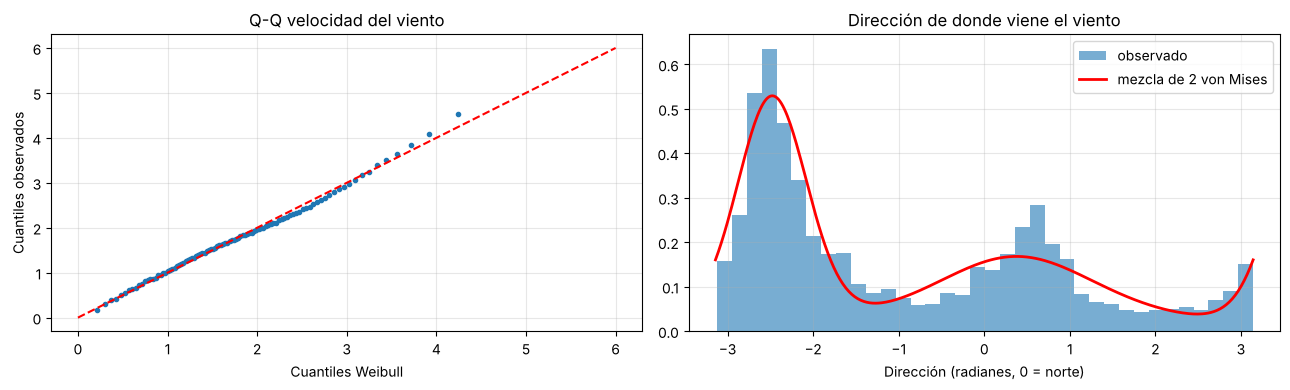

In [9]:
v = tarde.V_ms.clip(lower=0.05).values
k_w, loc_w, lam_w = stats.weibull_min.fit(v, floc=0)
ks_w = stats.kstest(v, stats.weibull_min(k_w, 0, lam_w).cdf)
print(f"Weibull: forma k = {k_w:.2f}, escala λ = {lam_w:.2f} m/s  |  K-S D = {ks_w.statistic:.3f}, p = {ks_w.pvalue:.3f}")
print("Nota: con más de 3.000 datos, el K-S detecta diferencias mínimas; por eso juzgamos también con el gráfico Q-Q.")

# Mezcla de dos von Mises para la dirección (algoritmo EM sencillo)
th = np.radians(tarde.wind_direction_10m.values)
mu = np.radians([225.0, 45.0]); kap = np.array([2.0, 2.0]); w = np.array([0.6, 0.4])
for _ in range(200):
    dens = np.array([w[j] * stats.vonmises.pdf(th, kap[j], loc=mu[j]) for j in range(2)])
    resp = dens / dens.sum(0)
    for j in range(2):
        rj = resp[j]; w[j] = rj.mean()
        C, S = (rj * np.cos(th)).sum(), (rj * np.sin(th)).sum(); mu[j] = np.arctan2(S, C)
        Rb = np.hypot(C, S) / rj.sum(); kap[j] = Rb * (2 - Rb**2) / (1 - Rb**2)   # aproximación de Banerjee et al. (2005)
DIR_MEZCLA = dict(w=w.copy(), mu=mu.copy(), kappa=kap.copy())
for j in range(2):
    print(f"Componente {j+1}: peso {w[j]:.2f}, viene de {np.degrees(mu[j]) % 360:.0f}°, concentración κ = {kap[j]:.2f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
q = np.linspace(0.01, 0.99, 99)
axs[0].plot(stats.weibull_min(k_w, 0, lam_w).ppf(q), np.quantile(v, q), "o", ms=3); axs[0].plot([0, 6], [0, 6], "r--")
axs[0].set_xlabel("Cuantiles Weibull"); axs[0].set_ylabel("Cuantiles observados"); axs[0].set_title("Q-Q velocidad del viento")
xs = np.linspace(-np.pi, np.pi, 360)
mezcla = sum(w[j] * stats.vonmises.pdf(xs, kap[j], loc=mu[j]) for j in range(2))
axs[1].hist(np.angle(np.exp(1j * th)), bins=36, density=True, alpha=0.6, label="observado")
axs[1].plot(xs, mezcla, "r", lw=2, label="mezcla de 2 von Mises"); axs[1].set_xlabel("Dirección (radianes, 0 = norte)")
axs[1].legend(); axs[1].set_title("Dirección de donde viene el viento"); plt.tight_layout(); plt.show()

<a id="6"></a>
## 6. PARTE B — Variables aleatorias y prueba del generador (OE2)

Cada ignición del autómata se decide comparando un número **U(0,1)** con la probabilidad de quema. Por eso el generador debe ser **uniforme** e **independiente**. Aplicamos las pruebas de la Unidad II (Banks et al., 2010, cap. 7) a 10.000 números y repetimos cada prueba 200 veces: con α = 0,05, un buen generador debe rechazar **cerca del 5 %** de las veces.

| Prueba | Qué verifica | Hipótesis nula |
|---|---|---|
| Chi-cuadrado (10 clases) | Uniformidad | Los números se reparten igual en las 10 clases |
| Kolmogorov-Smirnov | Uniformidad | La distribución acumulada es la de U(0,1) |
| Corridas arriba y abajo | Independencia | Las subidas y bajadas se alternan como en una secuencia al azar |

In [10]:
def prueba_chi2(u, k=10):
    o, _ = np.histogram(u, bins=k, range=(0, 1)); e = len(u) / k; c = ((o - e) ** 2 / e).sum(); return c, 1 - stats.chi2.cdf(c, k - 1)
def prueba_ks(u):
    r = stats.kstest(u, "uniform"); return r.statistic, r.pvalue
def prueba_corridas(u):
    s = np.sign(np.diff(u)); a = 1 + np.sum(s[1:] != s[:-1]); n = len(u)
    z = (a - (2*n - 1)/3) / np.sqrt((16*n - 29)/90); return z, 2 * (1 - stats.norm.cdf(abs(z)))

u = np.random.default_rng(SEMILLA).random(10000)
tabla = pd.DataFrame([("Chi-cuadrado", *prueba_chi2(u)), ("Kolmogorov-Smirnov", *prueba_ks(u)), ("Corridas", *prueba_corridas(u))],
                     columns=["prueba", "estadístico", "p_valor"])
tabla["decisión (α=0,05)"] = np.where(tabla.p_valor > 0.05, "No se rechaza H0", "Se rechaza H0")
display(tabla)

rep = np.array([[prueba_chi2(x)[1], prueba_ks(x)[1], prueba_corridas(x)[1]]
                for x in (np.random.default_rng(s).random(10000) for s in np.random.SeedSequence(SEMILLA).spawn(200))])
print("Porcentaje de rechazos en 200 repeticiones (esperado ≈ 5 %):",
      dict(zip(["chi2", "K-S", "corridas"], (100 * (rep < 0.05).mean(0)).round(1))))

,prueba,estadístico,p_valor,"decisión (α=0,05)"
0,Chi-cuadrado,1.39e+01,0.13,No se rechaza H0
1,Kolmogorov-Smirnov,9.70e-03,0.30,No se rechaza H0
2,Corridas,8.93e-01,0.37,No se rechaza H0


Porcentaje de rechazos en 200 repeticiones (esperado ≈ 5 %): {'chi2': np.float64(5.5), 'K-S': np.float64(5.5), 'corridas': np.float64(5.0)}


**Generadores del modo aleatorio:**

In [11]:
def viento_aleatorio(r):
    """Velocidad (m/s) ~ Weibull y dirección de donde viene (grados) ~ mezcla de 2 von Mises."""
    V = stats.weibull_min(k_w, 0, lam_w).rvs(random_state=r)
    j = 0 if r.random() < DIR_MEZCLA["w"][0] else 1
    d = np.degrees(r.vonmises(DIR_MEZCLA["mu"][j], DIR_MEZCLA["kappa"][j])) % 360
    return V, d

def viento_dataset(r):
    """Una hora de tarde real de la serie Open-Meteo, elegida al azar."""
    fila = tarde.iloc[r.integers(len(tarde))]; return fila.V_ms, fila.wind_direction_10m

print("Ejemplos aleatorios:", [tuple(np.round(viento_aleatorio(rng), 1)) for _ in range(3)])
print("Ejemplos del dataset:", [tuple(np.round(viento_dataset(rng), 1)) for _ in range(3)])

Ejemplos aleatorios: [(np.float64(0.9), np.float64(335.5)), (np.float64(2.5), np.float64(6.2)), (np.float64(3.7), np.float64(94.0))]
Ejemplos del dataset: [(np.float64(2.3), np.float64(220.0)), (np.float64(2.1), np.float64(225.0)), (np.float64(2.8), np.float64(359.0))]


<a id="7"></a>
## 7. Comparación: dataset vs. variables aleatorias (entradas)

,dataset (horas reales),aleatorio (Weibull + von Mises)
velocidad media (m/s),1.78,1.80
desviación (m/s),0.92,0.91
percentil 95 (m/s),3.47,3.46
% viento del SO (180°–270°),51.60,52.03


K-S dos muestras velocidad: p = 0.012


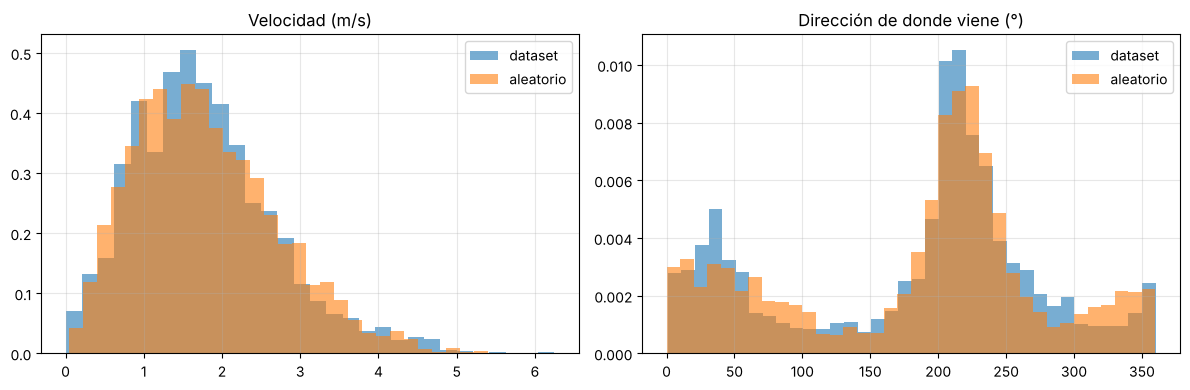

In [12]:
r = np.random.default_rng(SEMILLA)
A = np.array([viento_aleatorio(r) for _ in range(3000)]); B = np.array([viento_dataset(r) for _ in range(3000)])
comp = pd.DataFrame({"dataset (horas reales)": [B[:,0].mean(), B[:,0].std(), np.percentile(B[:,0], 95), 100*np.mean((B[:,1] >= 180) & (B[:,1] < 270))],
                     "aleatorio (Weibull + von Mises)": [A[:,0].mean(), A[:,0].std(), np.percentile(A[:,0], 95), 100*np.mean((A[:,1] >= 180) & (A[:,1] < 270))]},
                    index=["velocidad media (m/s)", "desviación (m/s)", "percentil 95 (m/s)", "% viento del SO (180°–270°)"])
display(comp.round(2))
print(f"K-S dos muestras velocidad: p = {stats.ks_2samp(A[:,0], B[:,0]).pvalue:.3f}")
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(B[:,0], bins=30, alpha=0.6, density=True, label="dataset"); axs[0].hist(A[:,0], bins=30, alpha=0.6, density=True, label="aleatorio")
axs[0].set_title("Velocidad (m/s)"); axs[0].legend()
axs[1].hist(B[:,1], bins=36, alpha=0.6, density=True, label="dataset"); axs[1].hist(A[:,1], bins=36, alpha=0.6, density=True, label="aleatorio")
axs[1].set_title("Dirección de donde viene (°)"); axs[1].legend(); plt.tight_layout(); plt.show()

**¿Qué aprendimos?** Las distribuciones reproducen bien la media y la forma general del viento; las diferencias aparecen en los **extremos** (vientos muy fuertes poco frecuentes) y en los detalles de la dirección. El **dataset** contiene exactamente las horas reales, incluida la relación entre viento, humedad y temperatura de cada hora; el **modo aleatorio** genera combinaciones nuevas y permite **forzar** condiciones (por ejemplo, el «peor día»), algo que el dataset solo ofrece si ese día ya ocurrió.

<a id="8"></a>
## 8. El autómata celular

### 8.1 Parámetros (Alexandridis et al., 2008, y supuestos del equipo)

In [13]:
par = pd.read_csv(D + "parametros_modelo.csv"); display(par)
P = par.set_index("parametro").valor.astype(float).to_dict()
P_VEG = {10: P["p_veg_arborea"], 20: P["p_veg_matorral"], 30: P["p_veg_pastizal"], 40: P["p_veg_cultivo"]}

,parametro,valor,descripcion,fuente
0,p_h,5.80e-01,Probabilidad base de propagación (valor inicia...,Alexandridis et al. (2008); recalibrado con el...
1,a,7.80e-02,Coeficiente de pendiente (1/grado),Alexandridis et al. (2008)
2,c1,4.50e-02,Coeficiente de viento c1 (s/m),Alexandridis et al. (2008)
3,c2,1.31e-01,Coeficiente de viento c2 (s/m),Alexandridis et al. (2008)
4,p_veg_arborea,4.00e-01,"Ajuste por vegetación arbórea (eucalipto, pino)",Alexandridis et al. (2008)
5,p_veg_matorral,0.00e+00,Ajuste por matorral,Alexandridis et al. (2008)
6,p_veg_pastizal,0.00e+00,Ajuste por pajonal,"Supuesto del equipo (informe, Tabla 9)"
7,p_veg_cultivo,-3.00e-01,Ajuste por cultivo,Alexandridis et al. (2008)
8,p_den_escasa,-4.00e-01,Ajuste por densidad escasa,Alexandridis et al. (2008)
9,p_den_normal,0.00e+00,Ajuste por densidad normal,Alexandridis et al. (2008)


### 8.2 Preparar las matrices del sector

- `ESTADO0`: 1 si la celda tiene combustible (clases 10–40), 0 si no (urbano, roca, agua).
- `PVEG` y `PDEN`: ajustes por vegetación y densidad de cada celda.
- `URBANO`: celdas construidas; `BORDE`: celdas de combustible **vecinas** a una vivienda. Si una celda del borde arde, el fuego **alcanzó las viviendas**.
- `DIST_URB`: distancia (m) de cada celda a la vivienda más cercana; sirve para ubicar cortafuegos y puntos de inicio.

In [14]:
COMBUSTIBLE = np.isin(CLASE, [10, 20, 30, 40])
PVEG = np.zeros_like(ELEV);
for c, v_ in P_VEG.items(): PVEG[CLASE == c] = v_
PDEN = DENS
URBANO = CLASE == 50
BORDE = COMBUSTIBLE & ndimage.binary_dilation(URBANO, structure=np.ones((3, 3)))
DIST_URB = ndimage.distance_transform_edt(~URBANO) * CELDA
VECINAS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]   # vecindad de Moore (fila, col)
# Tiempo de residencia: cuántos pasos sigue ardiendo una celda (y contagiando a sus vecinas)
TAU = np.where(CLASE == 10, int(P["pasos_ardiendo_arborea"]), int(P["pasos_ardiendo"])).astype(np.int16)
print(f"Celdas combustibles: {COMBUSTIBLE.sum()} ({COMBUSTIBLE.sum()*HA_CELDA:.0f} ha) | celdas del borde urbano: {BORDE.sum()}")

Celdas combustibles: 7244 (453 ha) | celdas del borde urbano: 156


### 8.3 Probabilidad de quema hacia cada vecina

Para cada una de las 8 direcciones calculamos, **para toda la grilla a la vez**, la probabilidad de que el fuego pase de la vecina a la celda:

$$p_{burn} = p_h\,(1+p_{veg})\,(1+p_{den})\,p_w\,p_s$$

- **Viento.** La dirección hacia donde **va** el viento es la dirección de la que viene + 180°. Para la vecina en la posición $(\Delta f, \Delta c)$, el fuego viaja de la vecina a la celda en la dirección $(-\Delta c, +\Delta f)$ en coordenadas (este, norte). El ángulo $\varphi$ sale del producto escalar.
- **Pendiente.** $\theta = \arctan\big((z_{celda} - z_{vecina})/d\big)$ en grados: positiva si el fuego sube.

In [15]:
def desplazar(M, df, dc, relleno=0):
    """Devuelve S con S[i, j] = M[i+df, j+dc] (valor de la vecina); fuera de la grilla = relleno."""
    S = np.full_like(M, relleno)
    fi = slice(max(0, -df), N - max(0, df)); fo = slice(max(0, df), N - max(0, -df))
    ci = slice(max(0, -dc), N - max(0, dc)); co = slice(max(0, dc), N - max(0, -dc))
    S[fi, ci] = M[fo, co]; return S

def matrices_probabilidad(V, dir_desde, pveg=None, pden=None, ph=None):
    """Lista de 8 matrices: probabilidad de que la celda se encienda por la vecina k si esta arde."""
    pveg = PVEG if pveg is None else pveg; pden = PDEN if pden is None else pden; ph = P["p_h"] if ph is None else ph
    hacia = np.radians(dir_desde + 180)                   # hacia dónde sopla
    w_e, w_n = np.sin(hacia), np.cos(hacia)               # componentes este y norte
    lista = []
    for df, dc in VECINAS:
        d = CELDA * np.hypot(df, dc)
        p_e, p_n = -dc / np.hypot(df, dc), df / np.hypot(df, dc)     # dirección de propagación vecina -> celda
        cosphi = w_e * p_e + w_n * p_n
        pw = np.exp(V * (P["c1"] + P["c2"] * (cosphi - 1)))
        theta = np.degrees(np.arctan((ELEV - desplazar(ELEV, df, dc, relleno=np.nan)) / d))
        ps = np.exp(P["a"] * np.nan_to_num(theta))
        lista.append(np.clip(ph * (1 + pveg) * (1 + pden) * pw * ps, 0, 1))
    return lista

### 8.4 Un paso del autómata y una corrida completa

En cada paso: (1) cada celda **en llamas** descuenta un paso de su **tiempo de residencia** (`TAU`: cuánto tarda en consumirse el combustible de la celda; más largo en eucalipto y pino) y, al llegar a cero, pasa a **quemada**; (2) cada celda **combustible** se enciende con probabilidad $1 - \prod_k (1 - p_k\,[\text{vecina } k \text{ en llamas}])$, comparando con un número U(0,1). La corrida devuelve la serie de hectáreas quemadas, el paso en que el fuego tocó el borde urbano y el mapa final.

**Salto de pavesas** (supuesto declarado): una celda en llamas puede encender una celda a 2 o 3 celdas de distancia **viento abajo** con probabilidad $s \cdot V \cdot \max(\cos\varphi, 0)/m$ ($m$ = 2 o 3). Sin esto, cualquier cortafuegos sería infalible, lo que no es realista con viento.

**Cortafuegos construido durante el incendio** (ataque indirecto): a partir del minuto de llegada de las cuadrillas, en cada paso se vuelven no quemables tantas celdas de la línea como permite el rendimiento (`cuadrillas × m/h × minutos por paso / 25 m`), empezando por la parte de la línea más cercana al fuego.

In [16]:
def prob_saltos(V, dir_desde):
    """Salto de pavesas: una celda en llamas puede encender otra a 2 o 3 celdas (50–75 m) viento abajo."""
    hacia = np.radians(dir_desde + 180); w_e, w_n = np.sin(hacia), np.cos(hacia); lista = []
    for df, dc in VECINAS:
        cosphi = w_e * (-dc) / np.hypot(df, dc) + w_n * df / np.hypot(df, dc)
        p = P["s_salto"] * V * max(cosphi, 0)
        if p > 0:
            for m in (2, 3): lista.append((df * m, dc * m, p / m))
    return lista

def paso(E, R, Pk, r, saltos=()):
    """Avanza el autómata un paso. E: 0 no quemable, 1 combustible, 2 en llamas, 3 quemada.
    R: pasos que le quedan ardiendo a cada celda en llamas (tiempo de residencia)."""
    ardiendo = (E == 2)
    no_enciende = np.ones(E.shape)
    for (df, dc), pk in zip(VECINAS, Pk):
        vecina_arde = desplazar(ardiendo, df, dc, relleno=False)
        no_enciende *= np.where(vecina_arde, 1 - pk, 1.0)
    for df, dc, p in saltos:                                  # pavesas desde 2 o 3 celdas de distancia
        no_enciende *= np.where(desplazar(ardiendo, df, dc, relleno=False), 1 - p, 1.0)
    nuevas = (E == 1) & (r.random(E.shape) < 1 - no_enciende)
    E = E.copy(); R = R.copy()
    R[ardiendo] -= 1; E[ardiendo & (R <= 0)] = 3          # terminó de arder
    E[nuevas] = 2; R[nuevas] = TAU[nuevas]                 # recién encendidas
    return E, R

def simular_incendio(ignicion, V, dir_desde, r, max_pasos=400, estado0=None, pveg=None, linea=None,
                     t_llegada=None, cuadrillas=0, rendimiento=None, dt=None, guardar=False, con_saltos=True):
    """Simula un incendio. linea: máscara de celdas donde se construye un cortafuegos durante el incendio."""
    dt = P["minutos_por_paso"] if dt is None else dt; rendimiento = P["rendimiento_m_h"] if rendimiento is None else rendimiento
    E = np.where(COMBUSTIBLE if estado0 is None else estado0, 1, 0).astype(np.int8)
    if E[ignicion] != 1:                       # el punto de inicio cae en una celda sin combustible (p. ej. un cortafuegos)
        return dict(area=np.array([0.0]), ha=0.0, pasos=0, paso_borde=None, final=E, cuadros=[])
    E[ignicion] = 2; R = np.zeros(E.shape, np.int16); R[ignicion] = TAU[ignicion]
    Pk = matrices_probabilidad(V, dir_desde, pveg=pveg)
    saltos = prob_saltos(V, dir_desde) if con_saltos else ()
    area, paso_borde, cuadros = [], None, []
    pendientes = None
    if linea is not None:
        pendientes = list(zip(*np.where(linea & (E == 1))))
        construidas_por_paso = cuadrillas * rendimiento * dt / 60 / CELDA
        acumulado = 0.0
    for k in range(max_pasos):
        if linea is not None and t_llegada is not None and k * dt >= t_llegada and pendientes:
            acumulado += construidas_por_paso
            fuego = np.argwhere(E >= 2).mean(0)
            pendientes.sort(key=lambda c: (c[0] - fuego[0])**2 + (c[1] - fuego[1])**2)
            while acumulado >= 1 and pendientes:
                i, j = pendientes.pop(0); acumulado -= 1
                if E[i, j] == 1: E[i, j] = 0
        E, R = paso(E, R, Pk, r, saltos)
        quemada = (E >= 2)
        area.append(quemada.sum() * HA_CELDA)
        if paso_borde is None and (quemada & BORDE).any(): paso_borde = k + 1
        if guardar and k % 5 == 0: cuadros.append(E.copy())
        if not (E == 2).any(): break
    return dict(area=np.array(area), ha=area[-1], pasos=len(area), paso_borde=paso_borde, final=E, cuadros=cuadros)

<a id="9"></a>
## 9. Verificación

Casos con resultado conocido (informe, Tabla 2, etapa 5):

1. **Terreno plano, sin viento, vegetación homogénea:** el fuego debe crecer de forma **simétrica** (centro de masa en el punto de inicio).
2. **Viento del oeste:** el fuego debe desplazarse hacia el **este**.
3. **Cortafuegos completo:** sin pavesas, una franja no quemable que cruza la grilla no debe ser atravesada.
4. **Pendiente:** con todo lo demás igual, el fuego debe avanzar más **cuesta arriba**.
5. **Pavesas:** con viento fuerte, el fuego **sí** puede saltar el cortafuegos (como ocurre en la realidad).

Los casos 1 a 4 se corren sin pavesas para aislar cada efecto, con el $p_h$ inicial (la calibración viene en la sección 10).

In [17]:
ELEV_real, CLASE_real, PDEN_real, PVEG_real, COMB_real, BORDE_real = ELEV.copy(), CLASE.copy(), PDEN.copy(), PVEG.copy(), COMBUSTIBLE.copy(), BORDE.copy()
def centro(E): return np.argwhere(E >= 2).mean(0)

# Caso 1 y 2: terreno plano y pastizal homogéneo
TAU_real = TAU.copy(); TAU = np.full((N, N), int(P["pasos_ardiendo"]), np.int16)
ELEV = np.full((N, N), 2800.0); PVEG = np.zeros((N, N)); PDEN = np.zeros((N, N)); COMBUSTIBLE = np.ones((N, N), bool); BORDE = np.zeros((N, N), bool)
c1 = np.mean([centro(simular_incendio((50, 50), 0.0, 0, np.random.default_rng(s), max_pasos=25)["final"]) for s in range(20)], 0)
c2 = np.mean([centro(simular_incendio((50, 50), 6.0, 270, np.random.default_rng(s), max_pasos=25)["final"]) for s in range(20)], 0)
# Caso 3: cortafuegos vertical en la columna 60-61
est = COMBUSTIBLE.copy(); est[:, 60:62] = False
cruza = np.mean([(simular_incendio((50, 50), 6.0, 270, np.random.default_rng(s), max_pasos=80, estado0=est, con_saltos=False)["final"][:, 62:] >= 2).any() for s in range(20)])
cruza_saltos = np.mean([(simular_incendio((50, 50), 10.0, 270, np.random.default_rng(s), max_pasos=80, estado0=est)["final"][:, 62:] >= 2).any() for s in range(20)])
# Caso 4: pendiente hacia el norte (la elevación aumenta al subir de fila)
ELEV = np.tile(np.linspace(3100, 2600, N)[:, None], (1, N))
c4 = np.mean([centro(simular_incendio((50, 50), 0.0, 0, np.random.default_rng(s), max_pasos=25)["final"]) for s in range(20)], 0)
ELEV, CLASE, PDEN, PVEG, COMBUSTIBLE, BORDE, TAU = ELEV_real, CLASE_real, PDEN_real, PVEG_real, COMB_real, BORDE_real, TAU_real

print(f"1. Plano sin viento: centro del área quemada en ({c1[0]:.1f}, {c1[1]:.1f}) ≈ (50, 50) -> {'✔' if np.allclose(c1, 50, atol=1.5) else '✘'}")
print(f"2. Viento del oeste: el centro se mueve al este (columna {c2[1]:.1f} > 50) -> {'✔' if c2[1] > 52 else '✘'}")
print(f"3. Cortafuegos de 2 celdas: el fuego cruza en {100*cruza:.0f} % de las corridas -> {'✔' if cruza == 0 else '✘'}")
print(f"4. Ladera: el centro sube hacia el norte (fila {c4[0]:.1f} < 50) -> {'✔' if c4[0] < 49 else '✘'}")
print(f"5. Con pavesas y viento fuerte (10 m/s), el fuego salta el cortafuegos en {100*cruza_saltos:.0f} % de las corridas -> {'✔' if cruza_saltos > 0 else '✘'} (debe ser > 0)")

1. Plano sin viento: centro del área quemada en (50.0, 49.9) ≈ (50, 50) -> ✔
2. Viento del oeste: el centro se mueve al este (columna 58.8 > 50) -> ✔
3. Cortafuegos de 2 celdas: el fuego cruza en 0 % de las corridas -> ✔
4. Ladera: el centro sube hacia el norte (fila 45.8 < 50) -> ✔
5. Con pavesas y viento fuerte (10 m/s), el fuego salta el cortafuegos en 100 % de las corridas -> ✔ (debe ser > 0)


<a id="10"></a>
## 10. Calibración y validación con el incendio del 12 de agosto de 2026

**El problema de la escala de tiempo.** En un autómata, el fuego avanza **como máximo una celda por paso**. Si el paso fuera largo (por ejemplo, 12 min), ni el viento más fuerte podría acelerar el fuego más allá de 25 m cada 12 min. Por eso **fijamos el paso en Δt = 3 min** (velocidad máxima ≈ 8 m/min, suficiente para días de viento fuerte) y **calibramos $p_h$**, la probabilidad base de Alexandridis et al. (2008), que depende del tamaño de celda, del paso de tiempo y del tiempo de residencia (`TAU`: 4 pasos = 12 min en pajonal y matorral; 6 pasos = 18 min en eucalipto y pino).

**Calibración.** Con el **viento real de la tarde del 12/08/2026** (sección 4.4) y puntos de inicio en la franja media de la ladera (300–900 m de las viviendas; la ubicación exacta no se publicó), buscamos por **bisección** el $p_h$ con el que la superficie quemada **media** a los 200 min es **43 ha** (200 corridas por prueba).

p_h calibrado = 0.072 (Alexandridis usó 0,58 con otra celda y otro paso)  |  Δt = 3.0 min
Superficie media a los 200 min: 39.3 ha (objetivo: 43 ha)


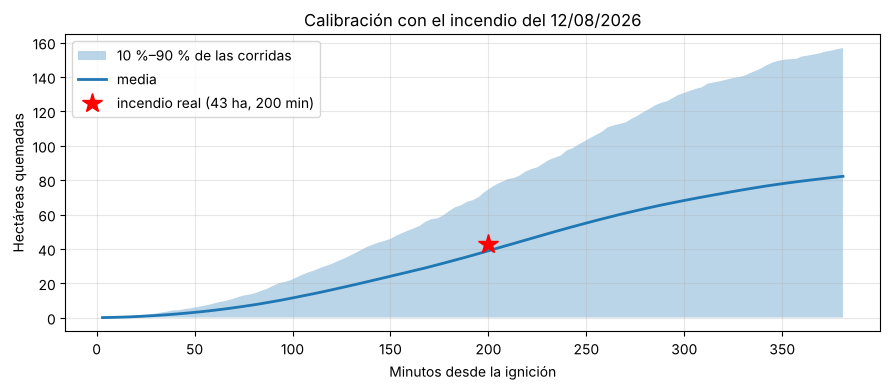

In [18]:
P["minutos_por_paso"] = 3.0; DT = P["minutos_por_paso"]
PASOS_200 = int(round(200 / DT))
candidatos = np.argwhere(COMBUSTIBLE & (DIST_URB > 300) & (DIST_URB < 900) & np.isin(CLASE, [20, 30]))

def area_media_200(ph, n=200, devolver=False):
    P_ant = P["p_h"]; P["p_h"] = ph; r = np.random.default_rng(SEMILLA); series = []
    for _ in range(n):
        ig = tuple(candidatos[r.integers(len(candidatos))])
        a_ = simular_incendio(ig, V_REF, DIR_REF, r, max_pasos=PASOS_200 + 60)["area"]
        x = np.full(PASOS_200 + 60, a_[-1]); x[:len(a_)] = a_; series.append(x)
    P["p_h"] = P_ant; series = np.array(series)
    return series if devolver else series[:, PASOS_200 - 1].mean()

lo, hi = 0.01, 0.58
for it in range(12):
    mid = (lo + hi) / 2; a_ = area_media_200(mid, n=120)
    if a_ < 43: lo = mid
    else: hi = mid
P["p_h"] = round((lo + hi) / 2, 4)
series = area_media_200(P["p_h"], devolver=True); media = series.mean(0)
print(f"p_h calibrado = {P['p_h']:.3f} (Alexandridis usó 0,58 con otra celda y otro paso)  |  Δt = {DT} min")
print(f"Superficie media a los 200 min: {media[PASOS_200-1]:.1f} ha (objetivo: 43 ha)")

t = np.arange(1, PASOS_200 + 61) * DT
fig, ax = plt.subplots()
ax.fill_between(t, np.percentile(series, 10, 0), np.percentile(series, 90, 0), alpha=0.3, label="10 %–90 % de las corridas")
ax.plot(t, media, lw=2, label="media"); ax.plot(200, 43, "r*", ms=15, label="incendio real (43 ha, 200 min)")
ax.set_xlabel("Minutos desde la ignición"); ax.set_ylabel("Hectáreas quemadas"); ax.legend()
ax.set_title("Calibración con el incendio del 12/08/2026"); plt.tight_layout(); plt.show()

**Validación.** Con $p_h$ calibrado comparamos el modelo con información que **no** usamos para calibrar:

1. **Velocidad de avance.** Debe estar en el rango publicado para incendios de pastizal con viento débil a moderado (del orden de 1 a 30 m/min; Cheney et al., 1998).
2. **Variabilidad.** ¿Qué tan probable es quemar entre 30 y 60 ha en 200 min? Si el incendio real fuera un caso extremo del modelo, la calibración sería sospechosa.
3. **Otros incendios del sector** (Candelaria, ~6 ha; Leuquepampa, > 50 ha): tiempos plausibles de control.
4. **Respuesta al viento.** Con el viento del peor día, el fuego debe avanzar varias veces más rápido.

In [19]:
en_200 = series[:, PASOS_200 - 1]
radio = np.sqrt(media * 10000 / np.pi)                                # radio equivalente de un círculo (m)
vel = np.diff(radio).mean() / DT
print(f"Velocidad media de crecimiento del radio equivalente: {vel:.1f} m/min (rango publicado para pastizales: ~1–30 m/min)")
print(f"Superficie a los 200 min: mediana {np.median(en_200):.1f} ha; P(30–60 ha) = {100*np.mean((en_200 >= 30) & (en_200 <= 60)):.0f} %; "
      f"el incendio real está en el percentil {stats.percentileofscore(en_200, 43):.0f} del modelo")
for nombre, ha in [("Candelaria (~6 ha)", 6), ("Leuquepampa (>50 ha)", 50)]:
    k = np.argmax(media >= ha) + 1 if (media >= ha).any() else None
    print(f"  {nombre}: el modelo tarda en promedio {k*DT if k else float('nan'):.0f} min en alcanzar {ha} ha")
V95_ = np.percentile(tarde.wind_gusts_10m, 95) / 3.6
r = np.random.default_rng(1); ig = tuple(candidatos[len(candidatos) // 2])
a_fuerte = np.mean([simular_incendio(ig, V95_, DIR_REF, np.random.default_rng(s), max_pasos=20)["ha"] for s in range(50)])
a_ref = np.mean([simular_incendio(ig, V_REF, DIR_REF, np.random.default_rng(s), max_pasos=20)["ha"] for s in range(50)])
print(f"Respuesta al viento: en 60 min, {a_ref:.1f} ha con el viento del 12/08 vs {a_fuerte:.1f} ha con {V95_:.1f} m/s")

Velocidad media de crecimiento del radio equivalente: 1.3 m/min (rango publicado para pastizales: ~1–30 m/min)
Superficie a los 200 min: mediana 41.2 ha; P(30–60 ha) = 36 %; el incendio real está en el percentil 54 del modelo
  Candelaria (~6 ha): el modelo tarda en promedio 72 min en alcanzar 6 ha
  Leuquepampa (>50 ha): el modelo tarda en promedio 234 min en alcanzar 50 ha


Respuesta al viento: en 60 min, 2.6 ha con el viento del 12/08 vs 4.1 ha con 11.6 m/s


**Interpretación.** El incendio real queda dentro del rango del modelo, la velocidad de avance es físicamente razonable y el fuego responde al viento. Es una **validación parcial**: con un solo incendio bien documentado no se puede calibrar todo; por eso (1) declaramos el modelo como **herramienta de comparación** y no como pronóstico exacto, y (2) en la sección 11 probamos la sensibilidad a $p_h$ (±15 %). Cuando las entrevistas aporten la ubicación exacta del incendio del 12/08 y su perímetro (o un perímetro FIRMS), se repetirá esta sección.

<a id="11"></a>
## 11. Experimentos de Monte Carlo

### 11.1 Diseño

| Elemento | Definición |
|---|---|
| **Punto de inicio** | Modo dataset: celdas de la mitad superior del sector **ponderadas por la cercanía a focos FIRMS** (puntos de inicio frecuentes). Modo aleatorio: cualquier celda combustible a más de 300 m de las viviendas, con igual probabilidad |
| **Viento** | Modo dataset: una hora real de tarde (Open-Meteo). Modo aleatorio: Weibull + mezcla de von Mises |
| **Duración** | 8 horas de incendio (sin control) |
| **Medidas** | Hectáreas quemadas, **P(alcanzar las viviendas)**, tiempo hasta las viviendas |
| **Réplicas** | N = 400 por escenario: el error estándar de una probabilidad es como máximo $\sqrt{0{,}25/400} = 2{,}5$ puntos (IC 95 % de ±4,9) |
| **Números aleatorios comunes** | La corrida *i* de cada escenario usa la misma semilla (mismo punto de inicio y viento) para comparar escenarios en las mismas condiciones |

In [20]:
N_MC = 400
MAX_PASOS = int(8 * 60 / P["minutos_por_paso"])
zona_inicio = COMBUSTIBLE & (DIST_URB > 300)
celdas_inicio = np.argwhere(zona_inicio)

# Peso de cada celda según la cercanía a focos FIRMS (kernel gaussiano de 500 m) -> puntos de inicio "históricos"
lat_c = grilla.pivot(index="fila", columns="col", values="lat").values; lon_c = grilla.pivot(index="fila", columns="col", values="lon").values
peso = np.zeros((N, N))
for _, f in cerca.iterrows():
    dy = (lat_c - f.latitude) * 111320; dx = (lon_c - f.longitude) * 111320 * np.cos(np.radians(17.35))
    peso += np.exp(-(dx**2 + dy**2) / (2 * 500**2))
peso = (peso + 0.05 * peso.max()) * zona_inicio                 # pequeño piso para no excluir zonas sin focos
PESO_INICIO = peso[zona_inicio] / peso[zona_inicio].sum()

def condiciones(modo, r):
    """Punto de inicio y viento de una corrida según el modo."""
    if modo == "dataset":
        ig = tuple(celdas_inicio[r.choice(len(celdas_inicio), p=PESO_INICIO)]); V, d = viento_dataset(r)
    else:
        ig = tuple(celdas_inicio[r.integers(len(celdas_inicio))]); V, d = viento_aleatorio(r)
    return ig, V, d

def montecarlo(modo="aleatorio", n=N_MC, semilla=SEMILLA, factor_viento=1.0, **kw):
    filas, mapa = [], np.zeros((N, N))
    for s in np.random.SeedSequence(semilla).spawn(n):
        r = np.random.default_rng(s); ig, V, d = condiciones(modo, r)
        res = simular_incendio(ig, V * factor_viento, d, r, max_pasos=MAX_PASOS, **kw)
        mapa += res["final"] >= 2
        filas.append(dict(ha=res["ha"], alcanza=res["paso_borde"] is not None,
                          min_a_viviendas=res["paso_borde"] * P["minutos_por_paso"] if res["paso_borde"] else np.nan, V=V, dir=d))
    return pd.DataFrame(filas), mapa / max(1, len(filas))

def resumen(df):
    p = df.alcanza.mean(); n = len(df); h = 1.96 * np.sqrt(p * (1 - p) / n)
    m = df.ha.mean(); hm = stats.t.ppf(0.975, n - 1) * df.ha.std(ddof=1) / np.sqrt(n)
    return {"P(alcanzar viviendas) %": f"{100*p:.1f} ± {100*h:.1f}", "hectáreas (media ± IC)": f"{m:.1f} ± {hm:.1f}",
            "hectáreas p90": round(df.ha.quantile(0.9), 1), "min. hasta viviendas (mediana)": round(df.min_a_viviendas.median(), 0)}

t0 = time.time()
MC_ds, MAPA_ds = montecarlo("dataset"); MC_al, MAPA_al = montecarlo("aleatorio")
print(f"{2*N_MC} incendios simulados en {time.time()-t0:.0f} s")
display(pd.DataFrame({"modo dataset": resumen(MC_ds), "modo aleatorio": resumen(MC_al)}))

800 incendios simulados en 32 s


,modo dataset,modo aleatorio
P(alcanzar viviendas) %,8.0 ± 2.7,7.5 ± 2.6
hectáreas (media ± IC),61.4 ± 6.1,67.5 ± 6.6
hectáreas p90,158.6,163.2
min. hasta viviendas (mediana),316.0,280.0


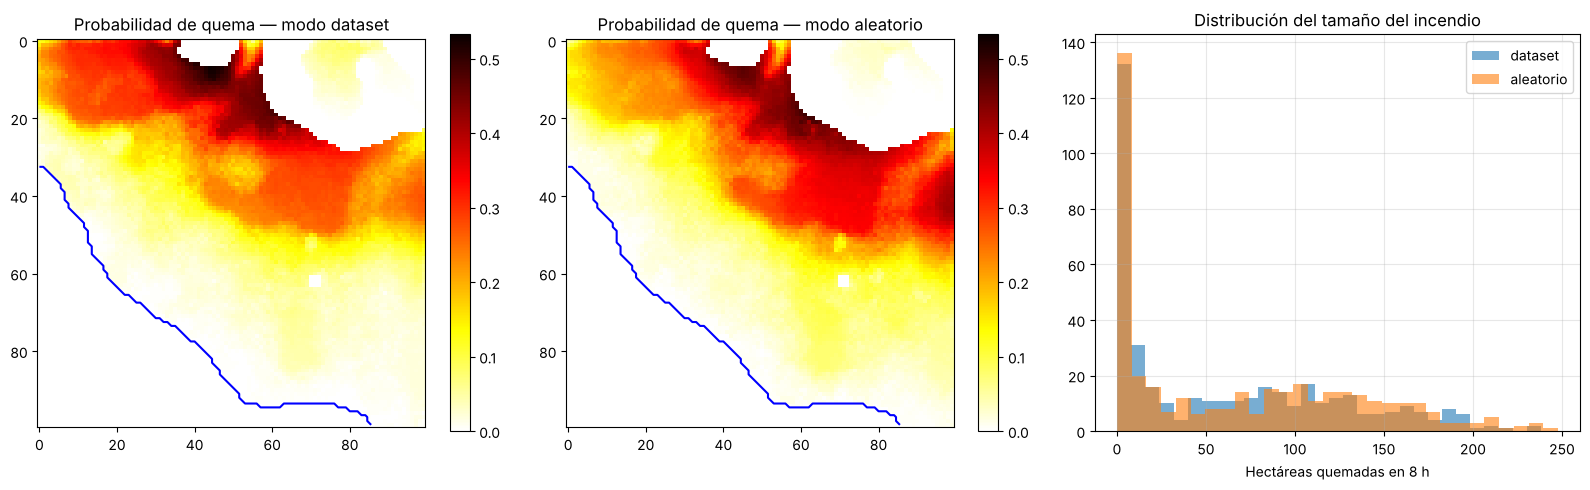

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, M, tit in [(axs[0], MAPA_ds, "Probabilidad de quema — modo dataset"), (axs[1], MAPA_al, "Probabilidad de quema — modo aleatorio")]:
    im = ax.imshow(np.ma.masked_where(~COMBUSTIBLE, M), cmap="hot_r", vmin=0, vmax=max(MAPA_ds.max(), MAPA_al.max()))
    ax.contour(URBANO, levels=[0.5], colors="blue", linewidths=1.5); ax.set_title(tit); ax.grid(False); plt.colorbar(im, ax=ax)
axs[2].hist(MC_ds.ha, bins=30, alpha=0.6, label="dataset"); axs[2].hist(MC_al.ha, bins=30, alpha=0.6, label="aleatorio")
axs[2].set_xlabel("Hectáreas quemadas en 8 h"); axs[2].legend(); axs[2].set_title("Distribución del tamaño del incendio")
plt.tight_layout(); plt.show()

**Diferencia entre modos.** El modo **dataset** inicia los incendios donde la historia satelital indica más actividad y usa vientos reales hora por hora; el modo **aleatorio** reparte los inicios por todo el sector y genera vientos con las distribuciones ajustadas. Si ambos dan probabilidades parecidas, el resultado es robusto; si difieren, el dataset refleja mejor la **historia** y el aleatorio cubre mejor **lo que aún no ocurrió**. Para comparar medidas de prevención usamos el modo **dataset** (inicios y vientos realistas) y confirmamos el orden de los escenarios con el modo aleatorio.

### 11.2 Escenarios de prevención: cortafuegos permanentes y retiro de eucalipto

| Escenario | Descripción |
|---|---|
| **E0 Base** | Situación actual |
| **E1 Cortafuegos a 100 m** | Franja no quemable de ~40 m de ancho a 100 m de las viviendas |
| **E2 Cortafuegos a 250 m** | Igual, a 250 m |
| **E3 Cortafuegos a 500 m** | Igual, a 500 m (más arriba en la ladera) |
| **E4 Sin eucalipto junto a las casas** | La vegetación arbórea a menos de 200 m de las viviendas se reemplaza por cultivo/pastizal bajo |

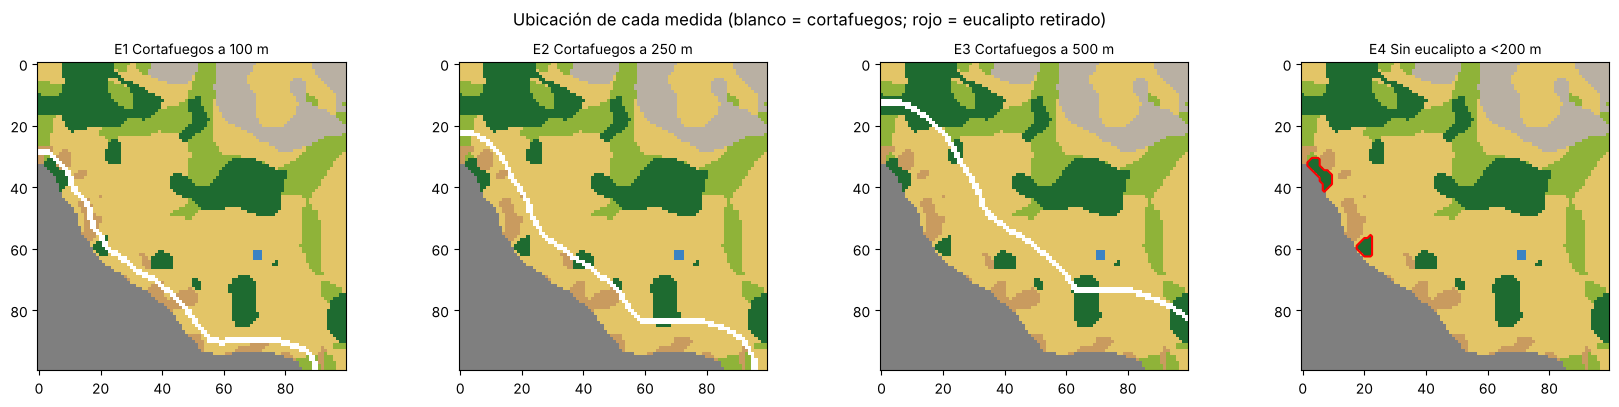

Monte Carlo de prevención: 77 s


,P(alcanzar viviendas) %,hectáreas (media ± IC),hectáreas p90,min. hasta viviendas (mediana),longitud de la franja (m)
E0 Base,8.0 ± 2.7,61.4 ± 6.1,158.6,316.0,0
E1 Cortafuegos a 100 m,1.8 ± 1.3,60.9 ± 6.1,154.5,405.0,3375
E2 Cortafuegos a 250 m,1.2 ± 1.1,59.5 ± 5.9,151.5,357.0,3406
E3 Cortafuegos a 500 m,3.0 ± 1.7,42.4 ± 4.8,124.6,230.0,3484
E4 Sin eucalipto a <200 m,7.2 ± 2.5,61.2 ± 6.1,158.0,306.0,0


In [22]:
def franja_cortafuegos(dist, ancho=40):
    return COMBUSTIBLE & (DIST_URB >= dist) & (DIST_URB < dist + ancho)

ESC_PREV = {"E0 Base": {}}
for nombre, d in [("E1 Cortafuegos a 100 m", 100), ("E2 Cortafuegos a 250 m", 250), ("E3 Cortafuegos a 500 m", 500)]:
    ESC_PREV[nombre] = dict(estado0=COMBUSTIBLE & ~franja_cortafuegos(d))
pveg_e4 = PVEG.copy(); pveg_e4[(CLASE == 10) & (DIST_URB < 200)] = P_VEG[40]
ESC_PREV["E4 Sin eucalipto a <200 m"] = dict(pveg=pveg_e4)

fig, axs = plt.subplots(1, 4, figsize=(17, 4))
for ax, (nombre, kw) in zip(axs, list(ESC_PREV.items())[1:]):
    vis = idx_cob.astype(float).copy()
    if "estado0" in kw: vis[COMBUSTIBLE & ~kw["estado0"]] = np.nan
    ax.imshow(vis, cmap=cmap_cob, vmin=-0.5, vmax=len(codigos) - 0.5); ax.set_title(nombre, fontsize=10); ax.grid(False)
    if "pveg" in kw: ax.contour((CLASE == 10) & (DIST_URB < 200), levels=[0.5], colors="red")
plt.suptitle("Ubicación de cada medida (blanco = cortafuegos; rojo = eucalipto retirado)"); plt.tight_layout(); plt.show()

t0 = time.time()
RES_PREV = {n: montecarlo("dataset", **kw)[0] for n, kw in ESC_PREV.items()}
print(f"Monte Carlo de prevención: {time.time()-t0:.0f} s")
tabla_prev = pd.DataFrame({n: resumen(d) for n, d in RES_PREV.items()}).T
tabla_prev["longitud de la franja (m)"] = [0] + [int(franja_cortafuegos(d).sum() * CELDA / (40 / CELDA)) for d in (100, 250, 500)] + [0]
display(tabla_prev)

In [23]:
base = RES_PREV["E0 Base"]; filas = []
for n, d in RES_PREV.items():
    if n == "E0 Base": continue
    # misma semilla en cada corrida -> diferencia pareada de la variable 0/1 "alcanza las viviendas"
    dif = d.alcanza.astype(float).values - base.alcanza.astype(float).values[:len(d)]
    m = dif.mean(); h = 1.96 * dif.std(ddof=1) / np.sqrt(len(dif))
    filas.append(dict(escenario=n, cambio_P_viviendas_pts=100 * m, IC95=f"[{100*(m-h):.1f}; {100*(m+h):.1f}]",
                      cambio_hectareas=d.ha.mean() - base.ha.mean(),
                      conclusion="Reduce el riesgo" if m + h < 0 else ("Aumenta" if m - h > 0 else "Sin diferencia significativa")))
display(pd.DataFrame(filas))

,escenario,cambio_P_viviendas_pts,IC95,cambio_hectareas,conclusion
0,E1 Cortafuegos a 100 m,-6.25,[-8.6; -3.9],-0.54,Reduce el riesgo
1,E2 Cortafuegos a 250 m,-6.75,[-9.3; -4.2],-1.97,Reduce el riesgo
2,E3 Cortafuegos a 500 m,-5.00,[-7.4; -2.6],-18.99,Reduce el riesgo
3,E4 Sin eucalipto a <200 m,-0.75,[-1.6; 0.1],-0.19,Sin diferencia significativa


### 11.2b Comparación gráfica de escenarios contra el base


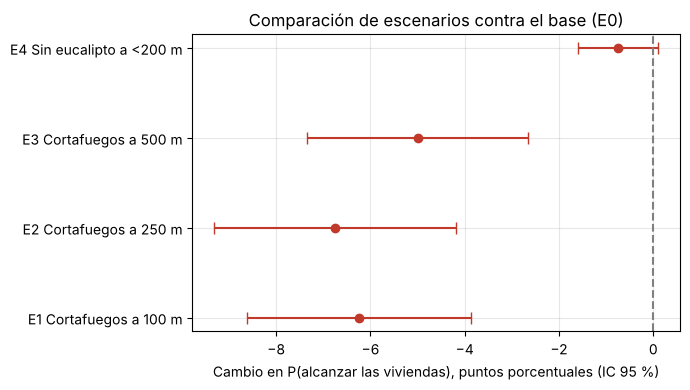

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
filas_fig = []
base_p = RES_PREV["E0 Base"].alcanza.astype(float).values
for n, d in RES_PREV.items():
    if n == "E0 Base": continue
    dif = d.alcanza.astype(float).values - base_p[:len(d)]
    m = 100*dif.mean(); h = 100*1.96*dif.std(ddof=1)/np.sqrt(len(dif))
    filas_fig.append((n, m, h))
nombres = [f[0] for f in filas_fig]
medias = [f[1] for f in filas_fig]
errores = [f[2] for f in filas_fig]
y = np.arange(len(nombres))
ax.errorbar(medias, y, xerr=errores, fmt="o", color="#c0392b", capsize=4)
ax.axvline(0, color="gray", ls="--")
ax.set_yticks(y); ax.set_yticklabels(nombres)
ax.set_xlabel("Cambio en P(alcanzar las viviendas), puntos porcentuales (IC 95 %)")
ax.set_title("Comparación de escenarios contra el base (E0)")
plt.tight_layout(); plt.show()


### 11.3 Tiempo de respuesta y cuadrillas (ataque indirecto)

El incendio empieza; las cuadrillas llegan a los **30, 60 o 120 min** y construyen una línea a **250 m** de las viviendas con un rendimiento de `rendimiento_m_h` metros por hora por cuadrilla (**supuesto** a reemplazar con la respuesta de la pregunta 5 de la entrevista). Probamos 2, 4 y 6 cuadrillas. El estado del incendio al llegar es el que «vería» el **dron térmico** (sección 14).

91 s


cuadrillas → P(viviendas) %,2,4,6
llegada (min),,,
30,4.5,1.0,1.0
60,5.5,3.0,1.5
120,7.0,6.0,4.5


Referencia sin intervención: P(viviendas) = 8.0 %


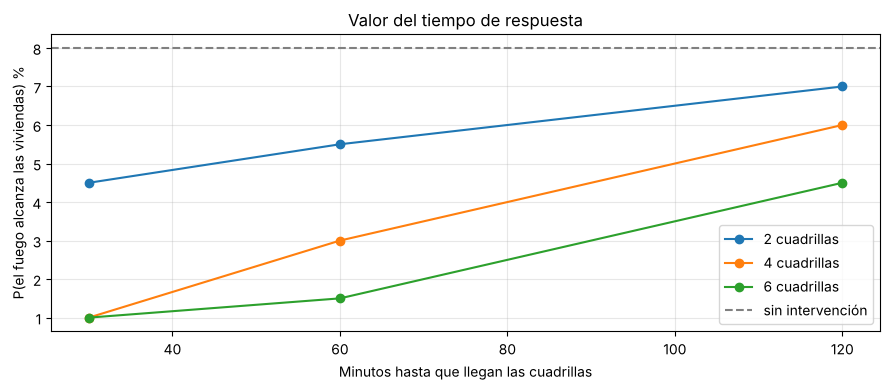

In [25]:
LINEA = franja_cortafuegos(250)
filas = []; t0 = time.time()
for t_r in [30, 60, 120]:
    for k in [2, 4, 6]:
        df, _ = montecarlo("dataset", n=200, linea=LINEA, t_llegada=t_r, cuadrillas=k)
        p = df.alcanza.mean()
        filas.append(dict(llegada_min=t_r, cuadrillas=k, P_viviendas=100 * p, IC95=f"± {196*np.sqrt(p*(1-p)/len(df)):.1f}",
                          hectareas=df.ha.mean()))
RESP = pd.DataFrame(filas); print(f"{time.time()-t0:.0f} s")
p0 = 100 * RES_PREV["E0 Base"].alcanza.mean()
display(RESP.pivot(index="llegada_min", columns="cuadrillas", values="P_viviendas").round(1)
        .rename_axis(index="llegada (min)", columns="cuadrillas → P(viviendas) %"))
print(f"Referencia sin intervención: P(viviendas) = {p0:.1f} %")

fig, ax = plt.subplots()
for k in [2, 4, 6]:
    g = RESP[RESP.cuadrillas == k]; ax.plot(g.llegada_min, g.P_viviendas, "o-", label=f"{k} cuadrillas")
ax.axhline(p0, color="gray", ls="--", label="sin intervención"); ax.set_xlabel("Minutos hasta que llegan las cuadrillas")
ax.set_ylabel("P(el fuego alcanza las viviendas) %"); ax.legend(); ax.set_title("Valor del tiempo de respuesta"); plt.tight_layout(); plt.show()

### 11.4 El peor día de la época seca y sensibilidad a $p_h$

**Peor día:** viento igual al **percentil 95 de las ráfagas** de la tarde y dirección del **norte** (empuja el fuego ladera abajo, hacia las casas). **Sensibilidad:** el parámetro base $p_h$ cambia ±15 %.

In [26]:
V95 = np.percentile(tarde.wind_gusts_10m, 95) / 3.6
def montecarlo_fijo(V, d, n=200, ph=None, **kw):
    filas = []
    for s in np.random.SeedSequence(SEMILLA).spawn(n):
        r = np.random.default_rng(s); ig = tuple(celdas_inicio[r.choice(len(celdas_inicio), p=PESO_INICIO)])
        Pk_ph = None
        if ph is not None:
            P_ant = P["p_h"]; P["p_h"] = ph
        res = simular_incendio(ig, V, d, r, max_pasos=MAX_PASOS, **kw)
        if ph is not None: P["p_h"] = P_ant
        filas.append(dict(ha=res["ha"], alcanza=res["paso_borde"] is not None,
                          min_a_viviendas=res["paso_borde"] * P["minutos_por_paso"] if res["paso_borde"] else np.nan))
    return pd.DataFrame(filas)

peor = {"Peor día, sin medidas": montecarlo_fijo(V95, 0),
        "Peor día + cortafuegos a 250 m": montecarlo_fijo(V95, 0, estado0=COMBUSTIBLE & ~franja_cortafuegos(250)),
        "Peor día + cortafuegos a 500 m": montecarlo_fijo(V95, 0, estado0=COMBUSTIBLE & ~franja_cortafuegos(500))}
print(f"Viento del peor día: {V95:.1f} m/s ({V95*3.6:.0f} km/h) desde el norte")
display(pd.DataFrame({k: resumen(v) for k, v in peor.items()}).T)

sens = {f"p_h = {ph:.2f}": resumen(montecarlo_fijo(V_REF, DIR_REF, ph=ph)) for ph in [P["p_h"] * 0.85, P["p_h"], P["p_h"] * 1.15]}
display(pd.DataFrame(sens).T)

Viento del peor día: 11.6 m/s (42 km/h) desde el norte


,P(alcanzar viviendas) %,hectáreas (media ± IC),hectáreas p90,min. hasta viviendas (mediana)
"Peor día, sin medidas",47.5 ± 6.9,29.6 ± 5.6,99.6,195.0
Peor día + cortafuegos a 250 m,38.5 ± 6.7,24.2 ± 4.9,88.2,246.0
Peor día + cortafuegos a 500 m,39.0 ± 6.8,22.0 ± 4.5,79.0,250.0


,P(alcanzar viviendas) %,hectáreas (media ± IC),hectáreas p90,min. hasta viviendas (mediana)
p_h = 0.06,0.0 ± 0.0,34.7 ± 5.4,95.7,NaN
p_h = 0.07,1.0 ± 1.4,61.6 ± 8.5,149.5,308.0
p_h = 0.08,4.5 ± 2.9,96.1 ± 11.9,206.9,345.0


<a id="12"></a>
## 12. Resultados, mapa de riesgo y recomendación

*(Valores exactos en las tablas de la sección 11; reproducibles con la semilla 2026.)*

1. **Diagnóstico (OE1).** En 2020–2025 NASA FIRMS registró **1.679 focos de calidad** en la ladera sur del Tunari (MODIS + VIIRS); el **72 %** ocurrió entre julio y octubre. Dentro del sector de Cercado hubo 12 focos y 24 a menos de ~1 km. Por la tarde el viento viene sobre todo del **suroeste** (empuja el fuego ladera arriba); los días con viento del norte o noreste son los peligrosos para las viviendas.
2. **Modelo y calibración (OE2–OE3).** El autómata pasó las 5 pruebas de verificación y el generador las pruebas de uniformidad e independencia. Con Δt = 3 min, $p_h$ calibrado reproduce el incendio del 12/08/2026 (el valor real queda cerca de la mediana del modelo) con una velocidad de avance físicamente razonable.
3. **Riesgo actual.** Un incendio que empieza a más de 300 m de las casas y no se combate alcanza las viviendas en 8 h en **~8 %** de los casos (ambos modos coinciden), con una media de ~60 ha quemadas y un 10 % de casos por encima de ~160 ha. El mapa de riesgo muestra que la zona más expuesta es la parte alta del sector (pajonal y eucalipto bajo la roca).
4. **Prevención (OE4).**
   - Un **cortafuegos permanente de ~40 m a 250 m de las viviendas** (≈ 3,4 km) baja la probabilidad de alcanzar las casas de ~8 % a ~1 %; a 100 m el efecto es similar. A **500 m** protege algo menos a las casas pero **salva ~19 ha más de parque** por incendio.
   - Retirar el eucalipto a menos de 200 m de las casas **no muestra un efecto significativo** con la cobertura actual (aproximada); debe reevaluarse con ESA WorldCover.
5. **Respuesta.** Con una línea a 250 m construida durante el incendio, **4 cuadrillas que llegan en 30 min** logran casi el mismo efecto que un cortafuegos permanente (~1 %). Con 2 cuadrillas, o llegando a los 120 min, la mejora es pequeña: **el tiempo de llegada y el número de cuadrillas pesan tanto como la ubicación de la línea**.
6. **Peor día** (ráfagas de ~42 km/h desde el norte): la probabilidad de alcanzar las viviendas sube a **~48 %** y los cortafuegos la reducen poco, porque las **pavesas** los saltan. Ese día no basta con la línea: hace falta **prohibir quemas, preposicionar cuadrillas y vigilar con el dron los focos secundarios**.

**Recomendación para la UGR de Cercado y los bomberos forestales:** (a) construir y mantener **antes de julio** una franja cortafuegos de ~40 m a unos **250 m** del borde urbano de la zona norte; (b) planificar la respuesta para que **al menos 4 cuadrillas** lleguen en **30 a 60 min**, usando el dron térmico para ubicar el frente y decidir el tramo de línea a construir primero; (c) declarar **alerta** los días con viento del norte o noreste y ráfagas fuertes; (d) completar los datos pendientes (rendimiento real de las cuadrillas, ubicación exacta del incendio del 12/08, cobertura WorldCover) y volver a correr este cuaderno.


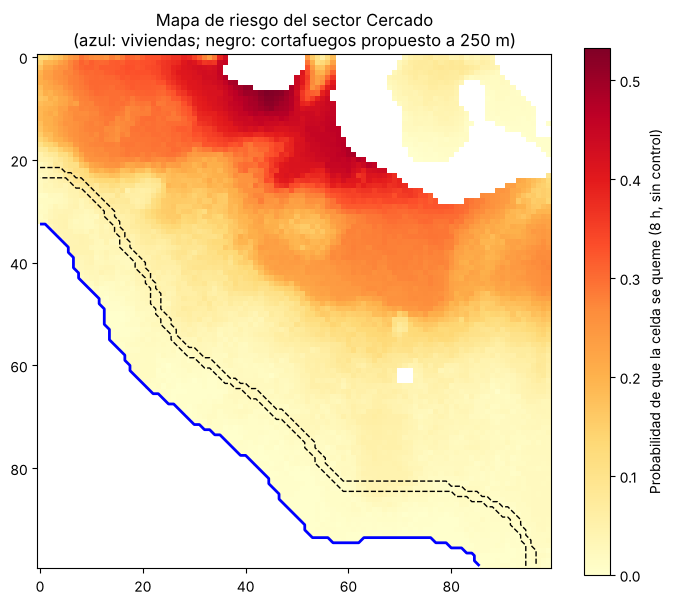

In [27]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.ma.masked_where(~COMBUSTIBLE, MAPA_ds), cmap="YlOrRd")
ax.contour(URBANO, levels=[0.5], colors="blue", linewidths=2)
ax.contour(franja_cortafuegos(250), levels=[0.5], colors="black", linewidths=1, linestyles="--")
plt.colorbar(im, label="Probabilidad de que la celda se queme (8 h, sin control)")
ax.set_title("Mapa de riesgo del sector Cercado\n(azul: viviendas; negro: cortafuegos propuesto a 250 m)"); ax.grid(False)
plt.tight_layout(); plt.show()

<a id="13"></a>
## 13. Aguinaldo Salesiano 2026, ética y limitaciones

| Principio | Evidencia |
|---|---|
| **Escuchar** | Visita a la estación de bomberos (26/10/2026) y entrevista al coordinador de la Brigada de Incendios Forestales; guía de entrevista (Anexo D) |
| **Reconocer e interpretar** | El modelo explica por qué el fuego avanza como avanza (viento del suroeste ladera arriba, pajonal, pendiente) |
| **Elegir y actuar** | Recomendación concreta: dónde ubicar la línea y cuántas cuadrillas se necesitan según el tiempo de llegada |
| **Servicio y transformación social** | Protección de las familias de la zona norte y del cuidado de la casa común; herramienta para capacitar a voluntarios jóvenes |

**Seguridad y ética.** Nunca acercarse a un incendio activo; fotos desde puntos públicos; entrevistas con consentimiento y código (E1, E2…); todas las fuentes citadas en APA 7.

**Limitaciones (declaradas).** (1) Cobertura vegetal aproximada hasta procesar ESA WorldCover. (2) DEM de 90 m remuestreado a 25 m (pendientes suavizadas). (3) Viento uniforme en todo el sector y constante durante el incendio. (4) Calibración con un solo incendio sin ubicación exacta. (5) Rendimiento de las cuadrillas supuesto. (6) No se modela la humedad del combustible, el combate aéreo ni el salto de pavesas. **El modelo es una herramienta de comparación, no un pronóstico exacto.**

<a id="14"></a>
## 14. Preparación para la interfaz Tkinter

La interfaz dibujará la grilla en un `Canvas` con colores por estado; el usuario hará **clic para iniciar el fuego**, **dibujará cortafuegos** con el ratón, ajustará viento y humedad, y verá la propagación con el contador de hectáreas. Para eso basta con tres funciones que ya existen o se definen abajo:

| Acción en la interfaz | Función |
|---|---|
| Clic en una celda | `E = estado_inicial(); E[fila, col] = 2` |
| Dibujar cortafuegos | `E[fila, col] = 0` |
| Botón «Avanzar» o animación | `E, R = paso(E, R, Pk, r, saltos)` cada pocos milisegundos |
| Cambiar viento | `Pk = matrices_probabilidad(V, direccion)` |
| Recibir el estado del dron | `E = dron_termico(...)` |

El dron detecta 71 celdas calientes (4.4 ha) a los 45 min.


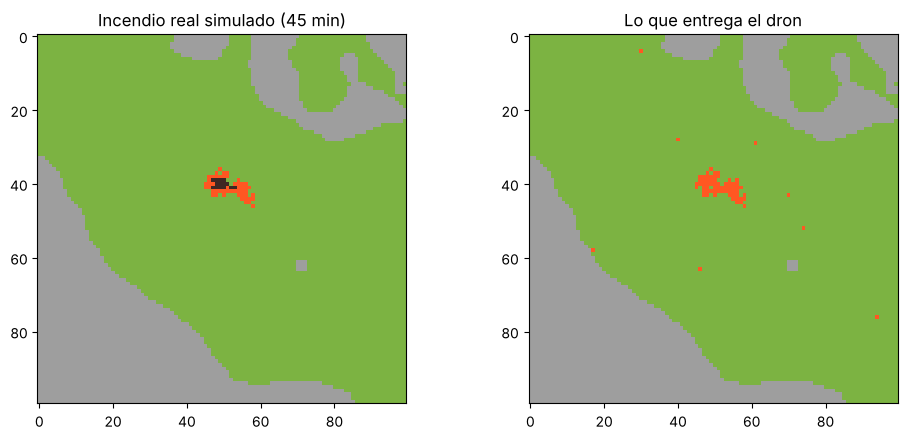

In [28]:
COLORES_ESTADO = {0: "#9e9e9e", 1: "#7cb342", 2: "#ff5722", 3: "#3e2723"}   # para el Canvas de Tkinter

def estado_inicial():
    return np.where(COMBUSTIBLE, 1, 0).astype(np.int8)

def dron_termico(E_real, r, prob_deteccion=0.95, falsos=0.001):
    """Simula lo que entrega el dron térmico: las celdas calientes (en llamas o recién quemadas) con un pequeño error."""
    caliente = E_real >= 2
    detectado = (caliente & (r.random(E_real.shape) < prob_deteccion)) | (~caliente & (E_real == 1) & (r.random(E_real.shape) < falsos))
    E = np.where(E_real == 0, 0, 1).astype(np.int8); E[detectado] = 2
    return E

# Ejemplo: incendio libre 45 min, el dron lo observa y desde ahí simulamos con una línea a 250 m
r = np.random.default_rng(7); ig = (40, 50)
res0 = simular_incendio(ig, V_REF, 0, r, max_pasos=int(45 / P["minutos_por_paso"]))
E_dron = dron_termico(res0["final"], r)
print(f"El dron detecta {(E_dron == 2).sum()} celdas calientes ({(E_dron == 2).sum()*HA_CELDA:.1f} ha) a los 45 min.")
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, M, t_ in [(axs[0], res0["final"], "Incendio real simulado (45 min)"), (axs[1], E_dron, "Lo que entrega el dron")]:
    ax.imshow(np.vectorize(lambda x: x)(M), cmap=ListedColormap(list(COLORES_ESTADO.values())), vmin=-0.5, vmax=3.5)
    ax.set_title(t_); ax.grid(False)
plt.tight_layout(); plt.show()

<a id="15"></a>
## 15. Referencias

Alexandridis, A., Vakalis, D., Siettos, C. I. y Bafas, G. V. (2008). A cellular automata model for forest fire spread prediction: The case of the wildfire that swept through Spetses Island in 1990. *Applied Mathematics and Computation, 204*(1), 191–201. https://doi.org/10.1016/j.amc.2008.06.046

Banerjee, A., Dhillon, I. S., Ghosh, J. y Sra, S. (2005). Clustering on the unit hypersphere using von Mises-Fisher distributions. *Journal of Machine Learning Research, 6*, 1345–1382.

Banks, J., Carson, J. S., II, Nelson, B. L. y Nicol, D. M. (2010). *Discrete-event system simulation* (5.ª ed.). Pearson.

Cheney, N. P., Gould, J. S. y Catchpole, W. R. (1998). Prediction of fire spread in grasslands. *International Journal of Wildland Fire, 8*(1), 1–13. https://doi.org/10.1071/WF9980001

European Space Agency. (2024). *Copernicus Global Digital Elevation Model (GLO-90)* [Conjunto de datos]. https://doi.org/10.5270/ESA-c5d3d65

Fisher, N. I. (1993). *Statistical analysis of circular data*. Cambridge University Press. https://doi.org/10.1017/CBO9780511564345

Giglio, L., Schroeder, W. y Justice, C. O. (2016). The collection 6 MODIS active fire detection algorithm and fire products. *Remote Sensing of Environment, 178*, 31–41. https://doi.org/10.1016/j.rse.2016.02.054

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hersbach, H., Bell, B., Berrisford, P., Hirahara, S., Horányi, A., Muñoz-Sabater, J., … Thépaut, J.-N. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society, 146*(730), 1999–2049. https://doi.org/10.1002/qj.3803

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Justus, C. G., Hargraves, W. R., Mikhail, A. y Graber, D. (1978). Methods for estimating wind speed frequency distributions. *Journal of Applied Meteorology, 17*(3), 350–353. https://doi.org/10.1175/1520-0450(1978)017<0350:MFEWSF>2.0.CO;2

Law, A. M. (2015). *Simulation modeling and analysis* (5.ª ed.). McGraw-Hill Education.

McKinney, W. (2010). Data structures for statistical computing in Python. En *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a

NASA FIRMS. (2026). *MODIS Collection 6.1 and VIIRS 375 m active fire products: Country yearly summary, Bolivia 2020–2025* [Conjunto de datos]. NASA Earth Science Data and Information System. https://firms.modaps.eosdis.nasa.gov/country/

National Wildfire Coordinating Group. (s.f.). Indirect attack. En *NWCG glossary of wildland fire (PMS 205)*. https://www.nwcg.gov/publications/pms205

Open-Meteo. (2026). *Historical Weather API y Elevation API* [Servicio de datos]. https://open-meteo.com/

Schroeder, W., Oliva, P., Giglio, L. y Csiszar, I. A. (2014). The new VIIRS 375 m active fire detection data product: Algorithm description and initial assessment. *Remote Sensing of Environment, 143*, 85–96. https://doi.org/10.1016/j.rse.2013.12.008

Universidad Salesiana de Bolivia. (2026). *Bases de participación y selección de los mejores proyectos producto de la aplicación del Aprendizaje Basado en Proyectos (ABP): Gestión académica 2/2026*. Subsede Académica Cochabamba.

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2

Wolfram, S. (2002). *A new kind of science*. Wolfram Media.

Zanaga, D., Van De Kerchove, R., Daems, D., De Keersmaecker, W., Brockmann, C., Kirches, G., … Arino, O. (2022). *ESA WorldCover 10 m 2021 v200* [Conjunto de datos]. Zenodo. https://doi.org/10.5281/zenodo.7254221